# m6A / RBP correlations

This notebook asks whether the **regulators of nuclear 3'UTR lengthening** (D22 → D35, CTRL; from `Figure_regulators_lengthening.ipynb`) act like m6A: does the Welch profile of their CLIP sites around the PAS look like the Welch profile of RMBase m6A sites? The **R2 regulators** (region 2, downstream of the proximal PAS) are split into APA and nuclear-retention (NR) regulators and compared with all other CLIP datasets. It was split out of an earlier, larger m6A notebook.

**Welch score** (`mean_score_lg10`): for each 50-nt bin around the proximal (pPAS) or distal (dPAS) poly(A) site, −log10(Welch p) × ΔPUD between 3'UTR pairs with and without a site (CLIP cross-link or m6A) in the bin, per day, fraction and genotype. Two profiles are compared with the Pearson r over the bins of a window (−150 to +150 nt around the pPAS for the proximal isoform, −150 to 0 nt around the dPAS for the distal isoform; `dist_min`, `dist_max_prox`, `dist_max_dist`).

**Inputs**
- MN_diff Welch profiles of every CLIP dataset, `MN_diff/results/3UTR_analysis/CLIP/analysis/welch_{proximal,distal}.csv`, and of the m6A sites, `MN_diff/results/RNA_modifs/m6A/welch/analysis/welch_{proximal,distal}.csv`.
- Per-condition RBP / modification correlations, `MN_diff/results/RNA_modifs/<modif>/welch/corr_RBP_<modif>_welch_dist_min_150.csv` (computed by the commented-out loop of the "Per-condition correlations" section).
- The regulators of lengthening, `../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_<region>_APA_vs_nuclear_retention_class.csv` (read with `utrals.figures.lengthening_regulators_csv`).

**Writes outside the repository**: the piled-up correlation tables `MN_diff/results/RNA_modifs/m6A/welch/corr_RBP_m6a_welch_piled_{alldays,D22D35_comp}_dist_min_150.csv`, read back by the next cell.

Figures are saved under `../Figures/Figure_m6A/m6A_RBP_profile_correlations/` and listed with their legends in `../Figures/README.md`.

## Contents

- Setup and data loading
- Per-condition correlations: `heatmap_m6A_RBP_correlation_over_days_R{1,2,3}_lengthening_regulators.pdf`, `boxplot_m6A_RBP_correlation_D35_NuclearWT_APA_NR_vs_other_{proximal,distal}_[<window>].pdf`
- Piled-up correlations (several conditions concatenated): `boxplot_piled_m6A_RBP_correlation_{D22_D35,all_days}_APA_NR_vs_all_proximal_[<window>]_distal_[<window>].pdf`
- Median Welch profiles per regulator category vs m6A, D22 and D35, proximal isoform: `lineplot_median_welch_profile_APA_NR_all_vs_m6A_proximal_{Nuclear,Cytoplasmic}_Wildtype_D22_D35.pdf`
- Median Welch profiles, D35, proximal vs distal isoform, with their Pearson r / RMSE / CCC to the m6A profile: `lineplot_median_welch_profile_APA_NR_all_vs_m6A_proximal_distal_{Nuclear,Cytoplasmic}_Wildtype_D35.pdf`, `barplot_median_welch_profile_APA_NR_all_vs_m6A_correlation_proximal_distal_{Nuclear,Cytoplasmic}_Wildtype_D35.pdf`

## Setup and data loading

Imports, output folder, the CLIP Welch profiles (`proximal`, `distal`), the correlation helpers (`safe_pearsonr`; `compute_rbp_modif_correlations`: per day × fraction × genotype and CLIP, Pearson r between the CLIP and the modification Welch profiles over the bins of the window, BH-corrected within each condition), the m6A Welch profiles (`proximal_m6A`, `distal_m6A`), and the correlation window.

In [1]:
import pandas as pd
import matplotlib

import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

In [2]:
figures_subfolder = "../Figures/Figure_m6A/m6A_RBP_profile_correlations"
import os

if not os.path.exists(f"{figures_subfolder}"):
    os.makedirs(f"{figures_subfolder}")

# save_figure saves a figure and lists it, with its legend, in ../Figures/README.md
from functools import partial
from utrals.paths import PROJECT_DIR  # data locations outside the repository (paths.env)
from utrals import figures
save_figure = partial(figures.save_figure, notebook="Figure_m6A_RBP_correlations.ipynb")
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run

In [3]:
proximal = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/CLIP/analysis/welch_proximal.csv", index_col=0)
distal = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/CLIP/analysis/welch_distal.csv", index_col=0)

In [4]:
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests

days = ["D0", "D3", "D7", "D14", "D22", "D35"]
compartments = ["Nuclear", "Cytoplasmic"]
genotypes = ["Wildtype", "VCP"]


def safe_pearsonr(x, y):
    """Pearson correlation after dropping NaN/inf pairs. Returns (n, r, p)."""
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    n = len(x)
    if n < 2 or np.std(x) == 0 or np.std(y) == 0:
        return n, np.nan, np.nan
    r, p = pearsonr(x, y)
    return n, r, p


def compute_rbp_modif_correlations(rbp_df, modif_df, isoform, dist_min, dist_max):
    """Per (Day, Compartment, VCP, CLIP) Pearson correlation between an RBP's
    binding profile and the modif profile, restricted to [dist_min, dist_max],
    with BH-FDR correction applied within each Day_Compartment_VCP group."""
    region = f"{dist_min}:{dist_max}"

    rbp_win = rbp_df[(rbp_df['dist'] >= dist_min) & (rbp_df['dist'] <= dist_max)]
    modif_win = modif_df[(modif_df['dist'] >= dist_min) & (modif_df['dist'] <= dist_max)]

    # One modif series per (Day, Compartment, VCP), indexed by dist for alignment.
    modif_groups = {
        key: g.set_index('dist')['mean_score_lg10']
        for key, g in modif_win.groupby(['Day', 'Compartment', 'VCP'])
    }

    records = []
    for (day, comp, genotype, rbp), sub_rbp in rbp_win.groupby(['Day', 'Compartment', 'VCP', 'CLIP']):
        modif_series = modif_groups.get((day, comp, genotype))
        if modif_series is None:
            continue

        # Join on 'dist' to guarantee correct pairing (rather than assuming matching sort order/length).
        rbp_series = sub_rbp.set_index('dist')['mean_score_lg10']
        aligned = rbp_series.to_frame('rbp').join(modif_series.rename('modif'), how='inner')

        n, r, p = safe_pearsonr(aligned['modif'].to_numpy(), aligned['rbp'].to_numpy())

        records.append({
            'RBP': rbp,
            'group': f"{day}_{comp}_{genotype}",
            'n': n,
            'r': r,
            'p_value': p,
            'Isoform': isoform,
            'Region': region,
        })

    df = pd.DataFrame(records)

    # BH-FDR correction within each group (i.e. across the RBPs tested together for that Day_Compartment_VCP).
    df['p_adj'] = np.nan
    valid = df['p_value'].notna()
    for _, idx in df[valid].groupby('group').groups.items():
        df.loc[idx, 'p_adj'] = multipletests(df.loc[idx, 'p_value'], method='fdr_bh')[1]

    return df[['RBP', 'group', 'n', 'r', 'p_value', 'p_adj', 'Isoform', 'Region']]


def get_RBP_name(clip_name):
    if "bestof" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "2016" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "all" not in clip_name:
        return clip_name.split('_')[0]        
    else:
        return clip_name.split('-')[1].upper()
    
def get_clip_name(clip_name):
    if "PTB" in clip_name:
        return "PTB"
    if "bestof" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "2016" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "all" not in clip_name and "iCLIP" not in clip_name:
        return clip_name.split('_')[0] + "_" + clip_name.split('_')[2]
    else:
        return clip_name.split('-')[1].upper()

In [5]:
path_to_m6A_welch = f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/m6A/welch/analysis"

proximal_m6A = pd.read_csv(os.path.join(path_to_m6A_welch, "welch_proximal.csv"), index_col=0)
distal_m6A = pd.read_csv(os.path.join(path_to_m6A_welch, "welch_distal.csv"), index_col=0)

In [6]:

dist_min = 150
dist_max_prox = 150
dist_max_dist = 0

## Per-condition correlations (one r per day, fraction and genotype)

The first cell holds the commented-out loop that computes, for every RNA modification, the correlation of each CLIP profile with the modification profile (`compute_rbp_modif_correlations`) and writes it to `MN_diff/results/RNA_modifs/<modif>/welch/corr_RBP_<modif>_welch_dist_min_150.{csv,xlsx}`; the next cell reads these files back.

The heatmaps show, for the regulators of lengthening of each region (rows = CLIP datasets, sorted by the D35 r), the r with the m6A profile at each day (columns), for the nuclear and cytoplasmic fractions of CTRL and VCP (panels) and both isoforms. The heatmap of all RBPs (`plot_r_heatmap`) is defined but its plotting loop is commented out. Saved: `heatmap_m6A_RBP_correlation_over_days_R{1,2,3}_lengthening_regulators.pdf`.

In [7]:
modifs = ["m1A", "m5C", "m6A", "m7G", "Nm", "Pseudo", "RNA-editing"]

# UNCOMMENT TO REGENERATE ALL CORRELATIONS FILES
# for modif in modifs:

#     path_to_modif_welch = f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/{modif}/welch/analysis"

#     proximal_modif = pd.read_csv(os.path.join(path_to_modif_welch, "welch_proximal.csv"), index_col=0)
#     distal_modif = pd.read_csv(os.path.join(path_to_modif_welch, "welch_distal.csv"), index_col=0)
    
#     proximal_corr_df = compute_rbp_modif_correlations(proximal, proximal_modif, isoform='proximal', dist_min=-dist_min, dist_max=dist_max_prox)
#     distal_corr_df = compute_rbp_modif_correlations(distal, distal_modif, isoform='distal', dist_min=-dist_min, dist_max=dist_max_dist)
#     correlations_df = pd.concat([proximal_corr_df, distal_corr_df], ignore_index=True)
#     correlations_df = correlations_df[correlations_df['n'] > 2]
#     correlations_df['CLIP']= correlations_df['RBP'].apply(get_clip_name)
#     correlations_df['RBP_short'] = correlations_df['RBP'].apply(get_RBP_name)
#     correlations_df.to_csv(f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/{modif}/welch/corr_RBP_{modif}_welch_dist_min_{dist_min}.csv")
#     correlations_df.to_excel(f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/{modif}/welch/corr_RBP_{modif}_welch_dist_min_{dist_min}.xlsx", index=False)





In [8]:
correlations_dfs = {}
for modif in modifs:

    correlations_dfs[modif] = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/{modif}/welch/corr_RBP_{modif}_welch_dist_min_{dist_min}.csv", index_col=0)

In [9]:
correlations_dfs['Pseudo'].sort_values('r')

,RBP,group,n,r,p_value,p_adj,Isoform,Region,CLIP,RBP_short
11722,all-eIF4E-FlpIn293-_iCLIP,D22_Nuclear_VCP,4,-0.999051,0.000949,0.195835,distal,-150:0,EIF4E,EIF4E
11712,all-Celf4-FlpIn293-_iCLIP,D22_Nuclear_VCP,4,-0.998831,0.001169,0.195835,distal,-150:0,CELF4,CELF4
14735,all-TIA1-Hela-_iCLIP,D35_Nuclear_Wildtype,4,-0.995872,0.004128,0.730312,distal,-150:0,TIA1,TIA1
14630,SF3B1_2_K652,D35_Nuclear_Wildtype,4,-0.995591,0.004409,0.730312,distal,-150:0,SF3B1_K652,SF3B1
13722,all-Celf4-FlpIn293-_iCLIP,D35_Cytoplasmic_VCP,4,-0.993363,0.006637,0.444702,distal,-150:0,CELF4,CELF4
...,...,...,...,...,...,...,...,...,...,...
11417,CSTF2_2_HepG2,D22_Nuclear_VCP,4,0.997273,0.002727,0.228360,distal,-150:0,CSTF2_HepG2,CSTF2
11467,FMR1_2_K652,D22_Nuclear_VCP,4,0.997275,0.002725,0.228360,distal,-150:0,FMR1_K652,FMR1
13422,CSTF2T_1_HepG2,D35_Cytoplasmic_VCP,4,0.998859,0.001141,0.191177,distal,-150:0,CSTF2T_HepG2,CSTF2T
14184,HNRNPM_2_HepG2,D35_Nuclear_VCP,4,0.999277,0.000723,0.242180,distal,-150:0,HNRNPM_HepG2,HNRNPM


In [10]:
# ===== RBP x m6A correlation heatmaps (r), one per Compartment_VCP condition and Isoform =====

day_order = ["D0", "D3", "D7", "D14", "D22", "D35"]

heatmap_dir = f"{figures_subfolder}"
os.makedirs(heatmap_dir, exist_ok=True)


def plot_r_heatmap(df, compartment, genotype, isoform, day_order=day_order, cmap='magma'):
    sub = df[df['group'].str.endswith(f"_{compartment}_{genotype}") & (df['Isoform'] == isoform)].copy()
    sub['Day'] = sub['group'].str.split('_').str[0]

    # Several CLIP datasets can map to the same RBP_short (replicates/cell lines);
    # average their r across those for a single per-RBP row.
    pivot = sub.pivot_table(index='RBP_short', columns='Day', values='r', aggfunc='mean')
    pivot = pivot.reindex(columns=day_order)
    pivot = pivot.dropna(how='all')
    

    # Keep NaN cells (missing Day/RBP combos) out of the clustering distance
    # computation, but leave them blank (masked) in the displayed heatmap.
    mask = pivot.isna()
    pivot_filled = pivot.fillna(0)

    n_rbp = pivot.shape[0]
    g = sns.clustermap(
        pivot_filled,
        mask=mask,
        row_cluster=True,
        col_cluster=False,
        cmap="Blues",
        vmin=0, vmax=1,
        figsize=(6, max(4, n_rbp * 0.18)),
        dendrogram_ratio=(0.15, 0.02),
        cbar_kws={'label': 'Pearson r'},
        cbar_pos=(1.02, 0.3, 0.03, 0.4),
        yticklabels=True
    )
    g.ax_heatmap.set_title(f"{compartment}_{genotype} ({isoform})", pad=20)
    g.ax_heatmap.set_xlabel('')
    g.ax_heatmap.set_ylabel('')
    g.ax_heatmap.tick_params(axis='y', labelsize=7)
    return g


conditions = [('Nuclear', 'Wildtype'), ('Nuclear', 'VCP'), ('Cytoplasmic', 'Wildtype'), ('Cytoplasmic', 'VCP')]
isoforms = ['proximal', 'distal']

# for compartment, genotype in conditions:
#     for isoform in isoforms:
#         g = plot_r_heatmap(correlations_dfs['m6A'], compartment, genotype, isoform)
#         save_figure(f"{heatmap_dir}/heatmap_m6A_RBP_correlation_over_days_{compartment}_{genotype}_{isoform}.pdf", fig=g.fig,
#                     legend=f"Pearson r between each RBP's CLIP Welch profile and the m6A Welch profile (MN "
#                            f"differentiation, {compartment} fraction, {genotype}, {isoform} isoform; bins from -150 to +150 nt around the pPAS for the proximal isoform, -150 to 0 nt around the dPAS for the distal isoform; "
#                            "corr_RBP_m6A_welch.csv), per day (columns D0-D35). One row per RBP (CLIP datasets of the "
#                            "same RBP averaged), rows clustered; colour scale 0-1 (negative r shown as 0); blank = not computed.")
#         plt.show()


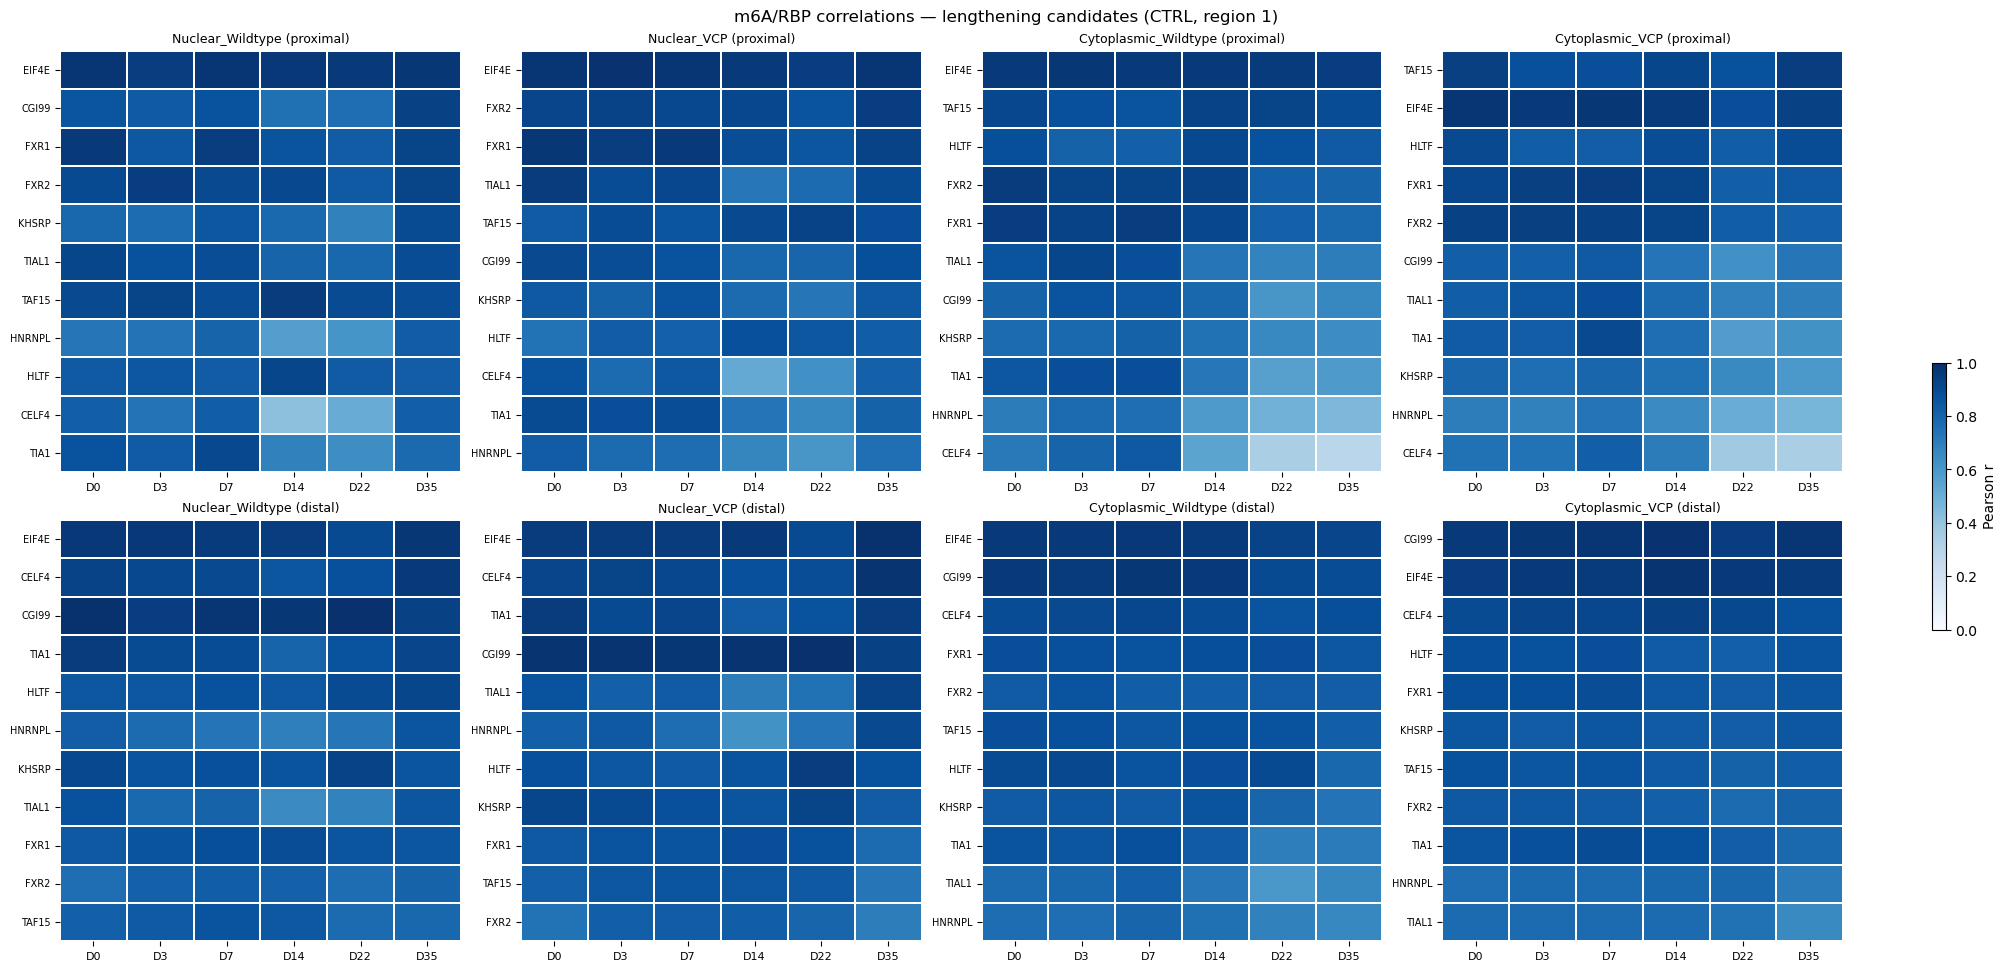

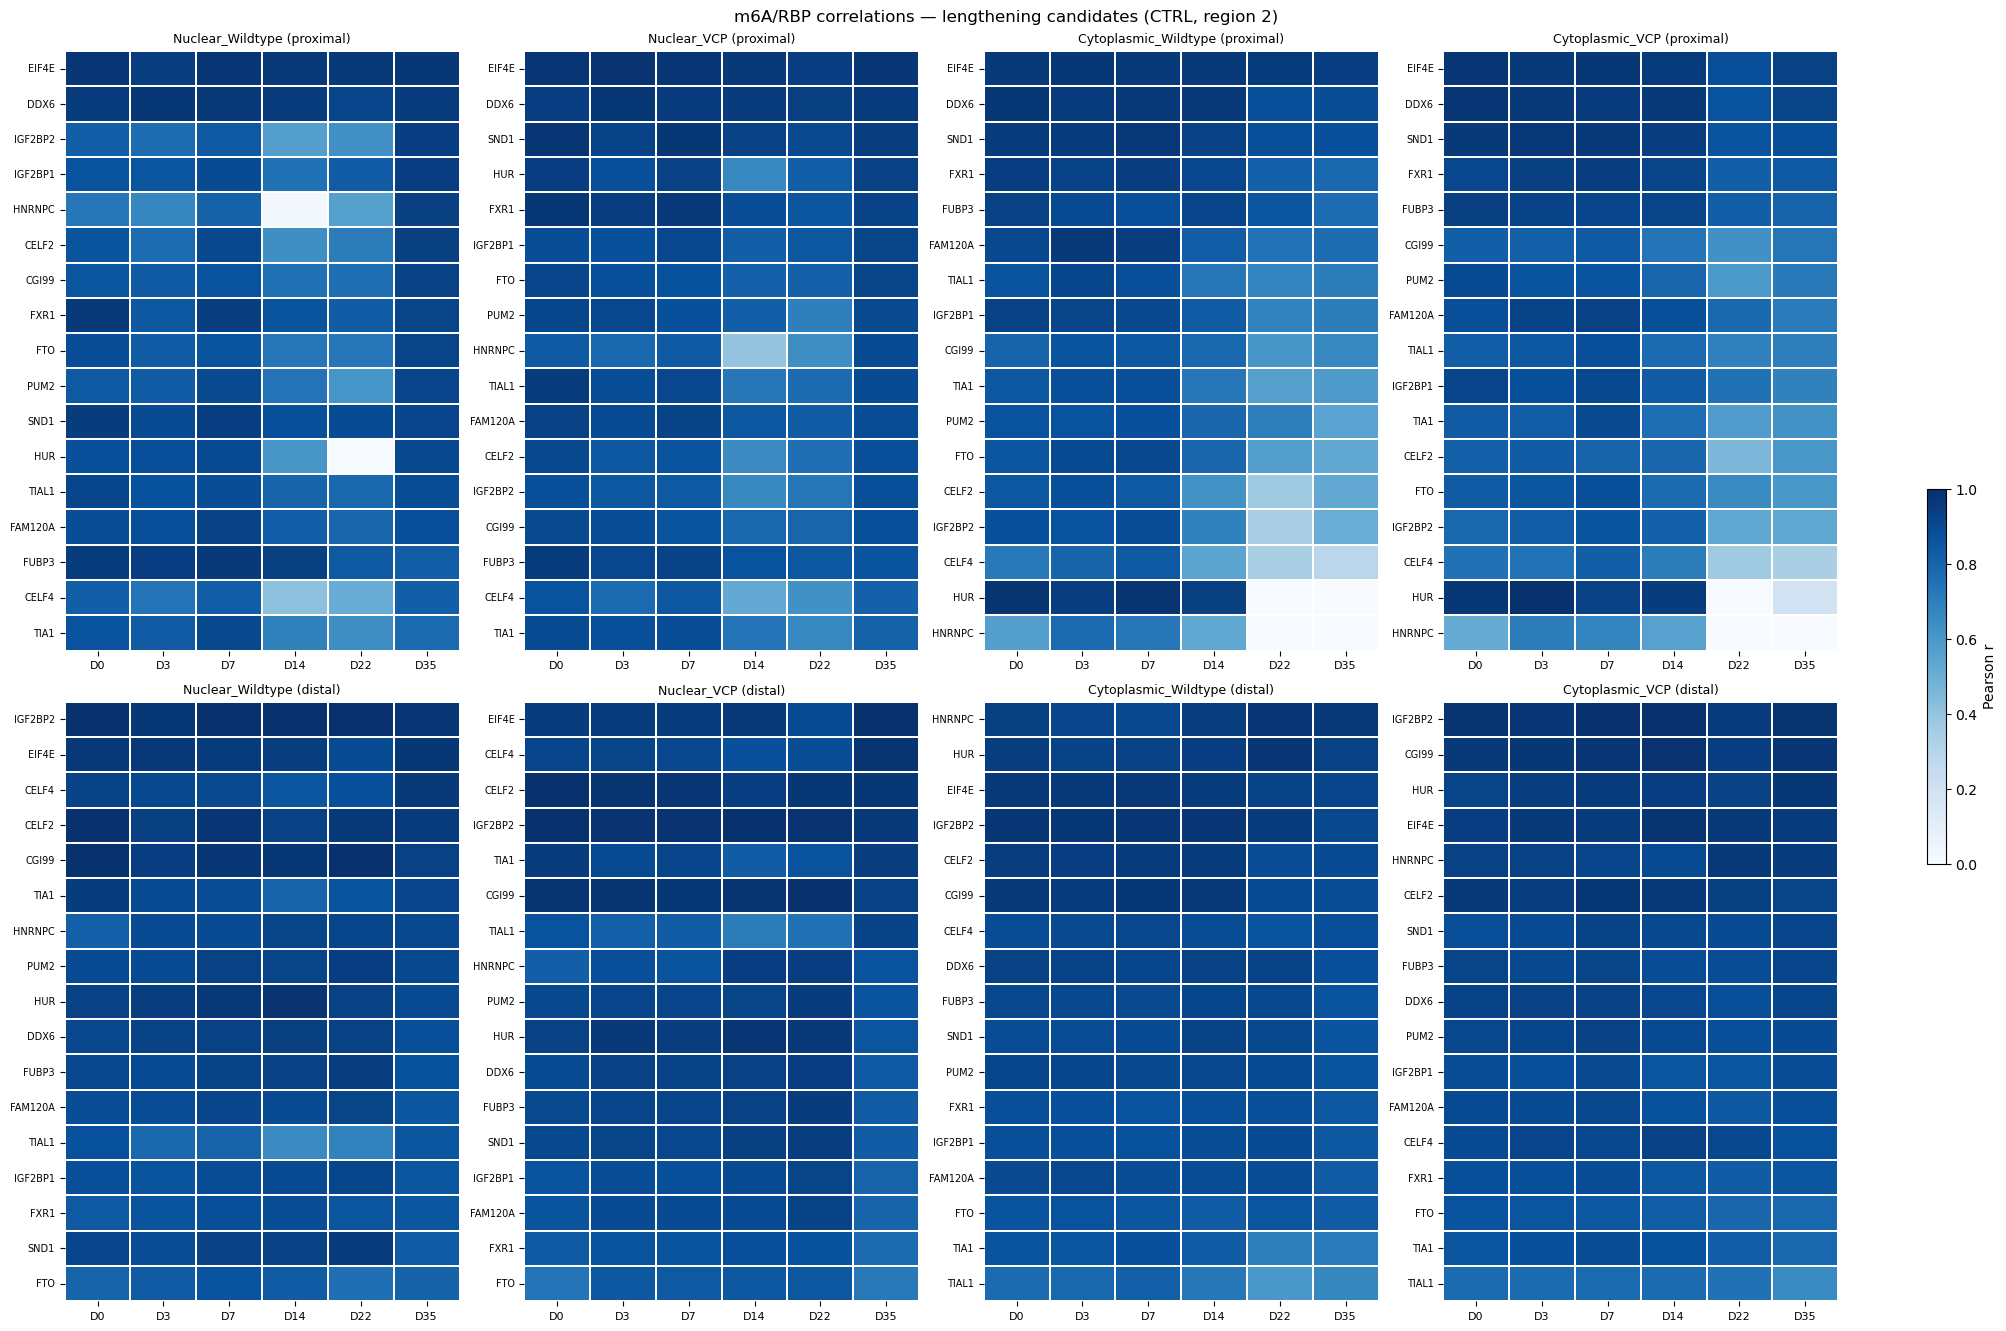

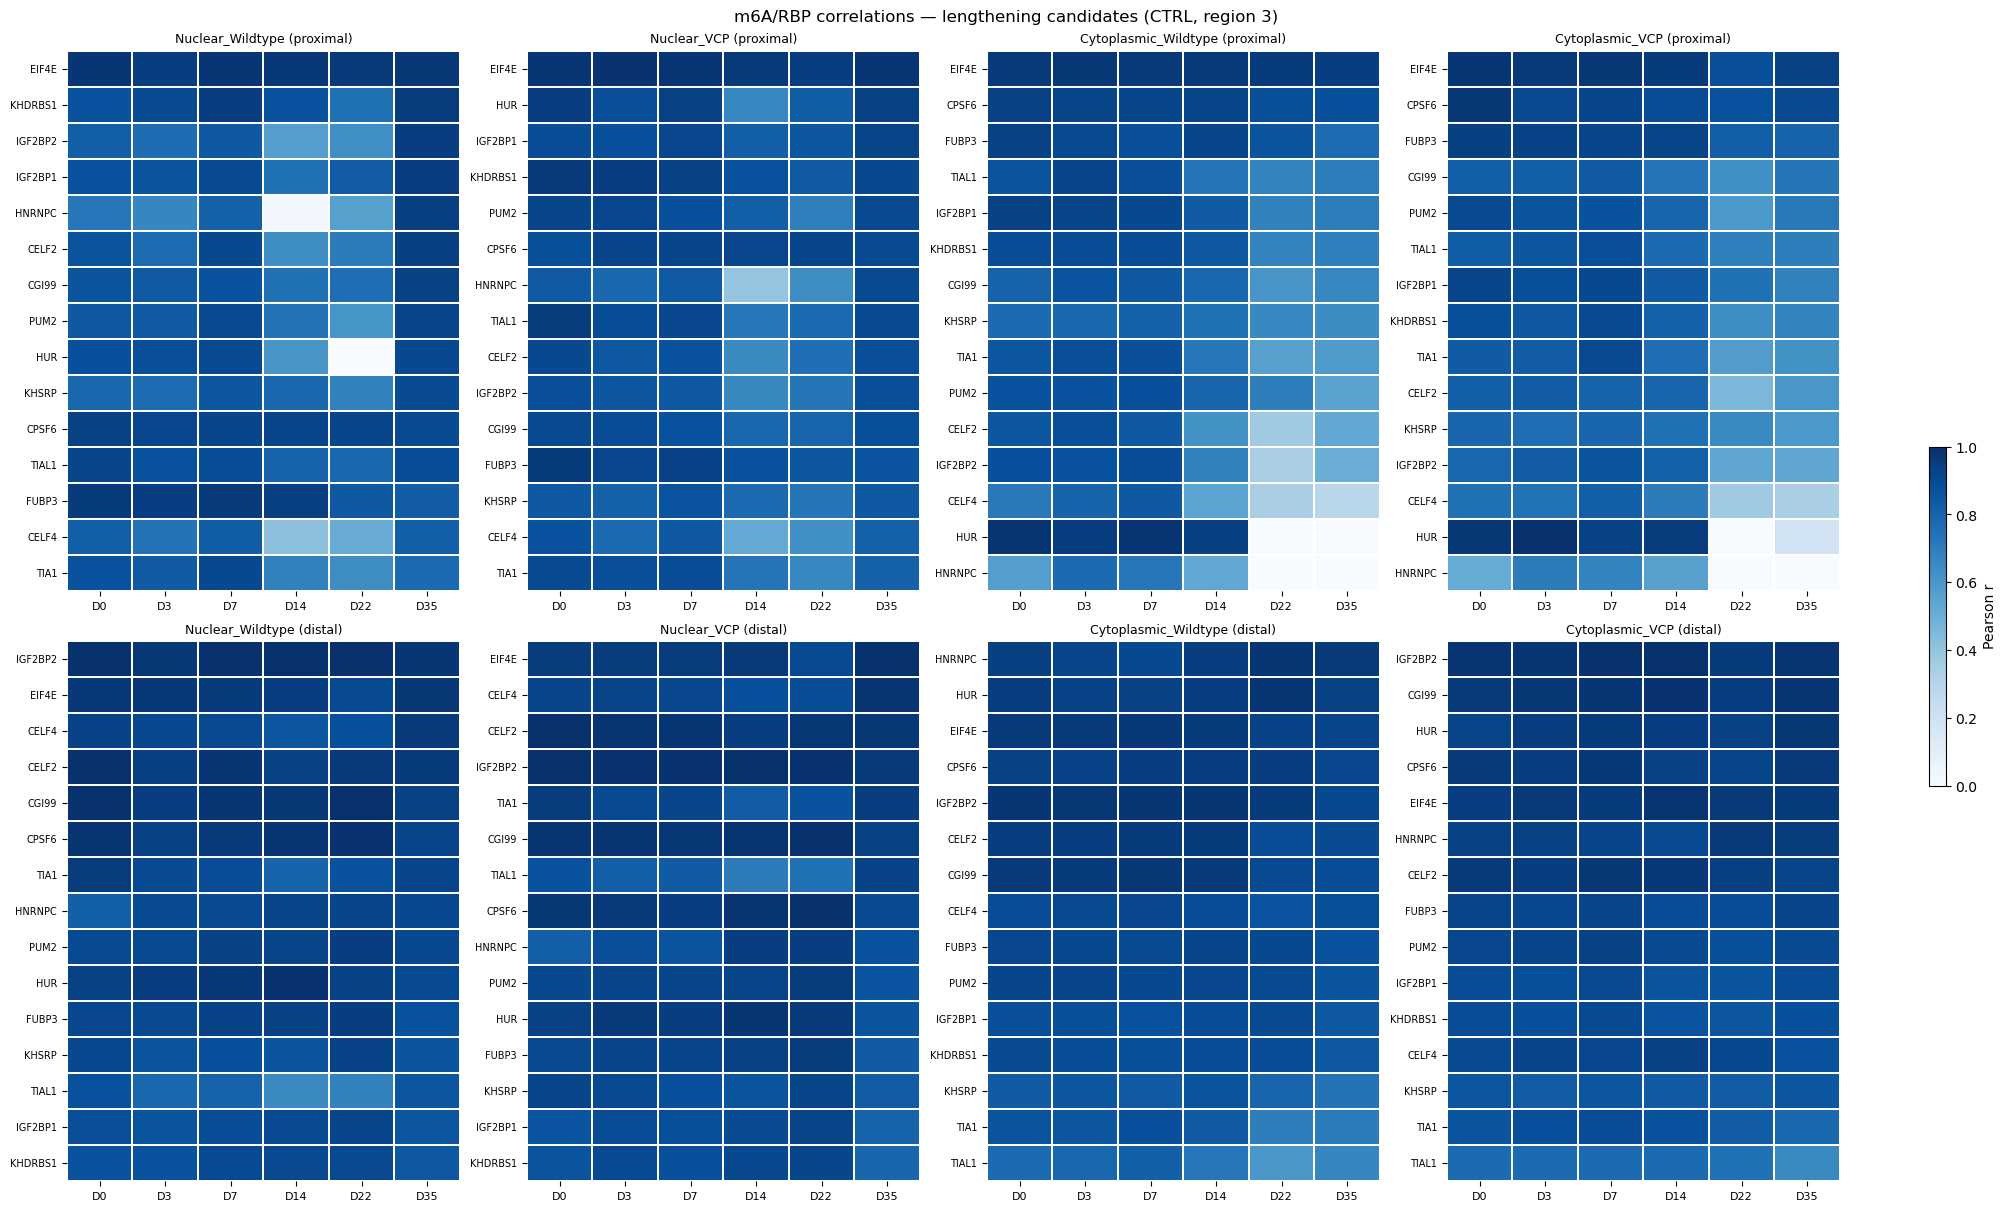

In [11]:
# ===== Same heatmaps restricted to the lengthening candidates of each region, rows sorted by D35 r =====

def plot_r_heatmap_candidates(ax, df, regulators, compartment, genotype, isoform, day_order=day_order):
    sub = df[df['group'].str.endswith(f"_{compartment}_{genotype}") & (df['Isoform'] == isoform)
             & df['RBP'].isin(list(regulators))].copy()
    sub['Day'] = sub['group'].str.split('_').str[0]

    # Candidates are specific CLIP datasets, so keep one row per dataset (no averaging across replicates)
    pivot = sub.pivot_table(index='RBP', columns='Day', values='r')
    pivot = pivot.reindex(columns=day_order).dropna(how='all')
    pivot = pivot.sort_values('D35', ascending=False, na_position='last')
    pivot.index = pivot.index.map(regulators)  # CLIP dataset -> RBP name

    sns.heatmap(pivot, ax=ax, cmap="Blues", vmin=0, vmax=1, cbar=False,
                yticklabels=True, linewidths=0.3, linecolor='white')
    ax.set_title(f"{compartment}_{genotype} ({isoform})", fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='y', labelsize=7)
    ax.tick_params(axis='x', labelsize=8)


for region in [1, 2, 3]:
    candidates = pd.read_csv(figures.lengthening_regulators_csv(region), index_col=0)
    regulators = dict(zip(candidates['regulator'], candidates['RBP']))

    fig, axes = plt.subplots(len(isoforms), len(conditions),
                             figsize=(5 * len(conditions), len(isoforms) * (0.3 * len(regulators) + 1.5)),
                             layout='constrained')
    for row, isoform in enumerate(isoforms):
        for col, (compartment, genotype) in enumerate(conditions):
            plot_r_heatmap_candidates(axes[row, col], correlations_dfs['m6A'], regulators,
                                      compartment, genotype, isoform)

    fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap="Blues"),
                 ax=axes, shrink=0.3, label='Pearson r')
    fig.suptitle(f"m6A/RBP correlations — lengthening candidates (CTRL, region {region})", fontsize=12)
    save_figure(f"{heatmap_dir}/heatmap_m6A_RBP_correlation_over_days_R{region}_lengthening_regulators.pdf", fig=fig,
                legend=f"Same m6A / CLIP Welch-profile correlations (Pearson r, bins from -150 to +150 nt around the pPAS for the proximal isoform, -150 to 0 nt around the dPAS for the distal isoform) restricted to the "
                       f"R{region} regulators of lengthening (Figure_regulators_lengthening.ipynb; one row "
                       "per CLIP dataset, sorted by D35 r), per day (columns D0-D35): proximal (top) and distal (bottom) "
                       "isoform, nuclear and cytoplasmic fractions of CTRL (Wildtype) and VCP cells. Colour scale 0-1.")
    plt.show()

### R2 regulators of lengthening vs other RBPs (D35, nuclear CTRL)

The next cells label every CLIP dataset APA or NR if it is an R2 regulator of lengthening of that class, Other otherwise (`regs_lengthening`, `regs_lengthening_apa`, `regs_lengthening_nr`), and compare the r of the three groups at D35 in nuclear CTRL, for each isoform: boxplot and beeswarm, two-sided Mann-Whitney tests NR vs Other and APA vs Other (uncorrected). Saved: `boxplot_m6A_RBP_correlation_D35_NuclearWT_APA_NR_vs_other_{proximal,distal}_[<window>].pdf`.

In [12]:
correlations_df = correlations_dfs['m6A'].copy()

In [13]:
correlations_df.sort_values('r', ascending=False)

,RBP,group,n,r,p_value,p_adj,Isoform,Region,CLIP,RBP_short
12051,all-IGF2BP2-Hela-_iCLIP,D22_Nuclear_Wildtype,4,0.996029,0.003971,0.306777,distal,-150:0,IGF2BP2,IGF2BP2
11709,all-CGI99-FlpIn293-_iCLIP,D22_Nuclear_VCP,4,0.995731,0.004269,0.263668,distal,-150:0,CGI99,CGI99
9031,all-Celf2-293Flp-_iCLIP,D0_Nuclear_VCP,4,0.995258,0.004742,0.350169,distal,-150:0,CELF2,CELF2
9366,all-Celf2-293Flp-_iCLIP,D0_Nuclear_Wildtype,4,0.995248,0.004752,0.328255,distal,-150:0,CELF2,CELF2
12044,all-CGI99-FlpIn293-_iCLIP,D22_Nuclear_Wildtype,4,0.993158,0.006842,0.306777,distal,-150:0,CGI99,CGI99
...,...,...,...,...,...,...,...,...,...,...
14096,CSTF2_1_HepG2,D35_Nuclear_VCP,4,-0.966166,0.033834,0.415789,distal,-150:0,CSTF2_HepG2,CSTF2
9122,FMR1_2_K652,D0_Nuclear_Wildtype,4,-0.967314,0.032686,0.328255,distal,-150:0,FMR1_K652,FMR1
14092,CSTF2T_1_HepG2,D35_Nuclear_VCP,4,-0.975634,0.024366,0.415789,distal,-150:0,CSTF2T_HepG2,CSTF2T
14147,FMR1_2_K652,D35_Nuclear_VCP,4,-0.979116,0.020884,0.415789,distal,-150:0,FMR1_K652,FMR1


In [14]:
correlations_df.replace("proximal", "Proximal 3'UTR Isoform", inplace=True)
correlations_df.replace("distal","Distal 3'UTR Isoform", inplace=True)


In [15]:
candidates_R2 = pd.read_csv(figures.lengthening_regulators_csv(2))

In [16]:
regs_lengthening_apa = list(candidates_R2[candidates_R2['category'] == 'APA']['RBP'].values)

regs_lengthening_nr = list(candidates_R2[candidates_R2['category'] == 'Nuclear retention']['RBP'].values)


In [17]:
candidates_R2 = pd.read_csv(figures.lengthening_regulators_csv(2), index_col=0)
regs_lengthening = list(candidates_R2['regulator'].values)
regs_lengthening_apa = list(candidates_R2[candidates_R2['category'] == 'APA']['regulator'].values)

regs_lengthening_nr = list(candidates_R2[candidates_R2['category'] == 'Nuclear retention']['regulator'].values)


In [18]:
correlations_df['regs_lengthening'] = correlations_df['RBP'].apply(lambda x: 'NR' if x in regs_lengthening else 'Other')
correlations_df['regs_lengthening'] = correlations_df.apply(lambda row: 'APA' if row['RBP'] in regs_lengthening_apa else row['regs_lengthening'], axis=1)



Other vs. APA: Custom statistical test, P_val:7.202e-04
Other vs. NR: Custom statistical test, P_val:8.312e-03


Other vs. APA: Custom statistical test, P_val:7.202e-04
Other vs. NR: Custom statistical test, P_val:8.312e-03


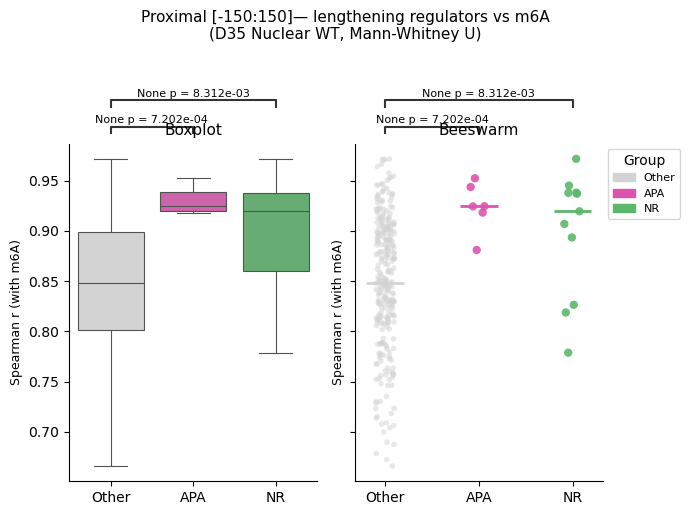

Other vs. APA: Custom statistical test, P_val:1.638e-01
Other vs. NR: Custom statistical test, P_val:3.517e-06


Other vs. APA: Custom statistical test, P_val:1.638e-01
Other vs. NR: Custom statistical test, P_val:3.517e-06


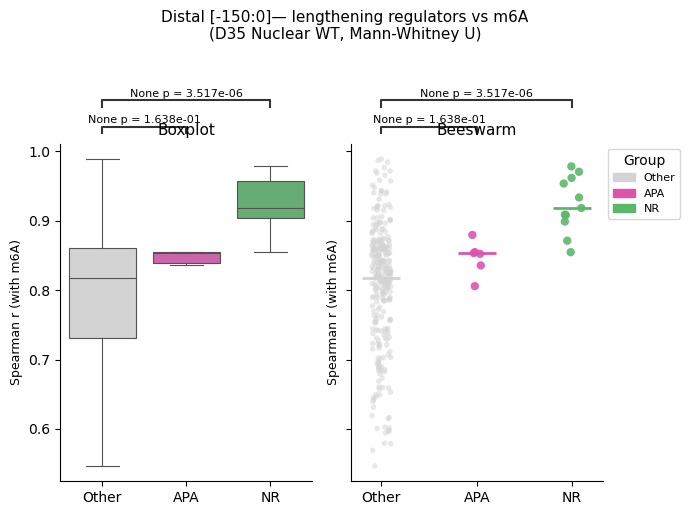

In [19]:

import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations
from statannotations.Annotator import Annotator
from matplotlib.patches import Patch

# ── data ──────────────────────────────────────────────────────────────────────
plot_df = correlations_df[
    (correlations_df['group'] == 'D35_Nuclear_Wildtype') &
    (correlations_df['Isoform'].isin(["Proximal 3'UTR Isoform", "Distal 3'UTR Isoform"]))
].copy()

plot_df['Isoform_short'] = plot_df['Isoform'].map({
    "Proximal 3'UTR Isoform": "Proximal",
    "Distal 3'UTR Isoform": "Distal"
})

hue_order = ['Other', 'APA', 'NR']
palette   = {'Other': '#d3d3d3', 'NR': '#5cb76b', 'APA': '#dd54af'}


def make_isoform_figure(plot_df, iso,  dist_min, dist_max, filename,):
    """Boxplot + beeswarm for a single isoform, NR vs Other and APA vs Other."""
    iso_df = plot_df[plot_df['Isoform_short'] == iso].copy()

    # Mann-Whitney: NR vs Other and APA vs Other
    other = iso_df[iso_df['regs_lengthening'] == 'Other']['r'].dropna()
    mw_pairs, mw_pvals = [], []
    for grp in ['NR', 'APA']:
        grp_vals = iso_df[iso_df['regs_lengthening'] == grp]['r'].dropna()
        if len(other) >= 3 and len(grp_vals) >= 3:
            _, pval = stats.mannwhitneyu(other, grp_vals, alternative='two-sided')
            mw_pairs.append(('Other', grp))
            mw_pvals.append(pval)

    fig, axes = plt.subplots(1, 2, figsize=(7, 5), sharey=True)

    for ax, plot_type in zip(axes, ['box', 'beeswarm']):
        if plot_type == 'box':
            sns.boxplot(
                data=iso_df, x='regs_lengthening', y='r',
                order=hue_order, palette=palette,
                showfliers=False, ax=ax, linewidth=0.8
            )
            ax.set_title('Boxplot', fontsize=11)
        else:
            # Other in background, NR and APA on top
            sns.stripplot(
                data=iso_df[iso_df['regs_lengthening'] == 'Other'],
                x='regs_lengthening', y='r', order=hue_order,
                color=palette['Other'], size=4, jitter=True, alpha=0.5, ax=ax, zorder=1
            )
            for grp in ['NR', 'APA']:
                sns.stripplot(
                    data=iso_df[iso_df['regs_lengthening'] == grp],
                    x='regs_lengthening', y='r', order=hue_order,
                    color=palette[grp], size=6, jitter=True, alpha=0.9, ax=ax, zorder=2
                )
            # Median lines
            for xi, grp in enumerate(hue_order):
                vals = iso_df[iso_df['regs_lengthening'] == grp]['r'].dropna()
                if len(vals):
                    ax.hlines(vals.median(), xi - 0.2, xi + 0.2,
                              colors=palette[grp], linewidths=2, zorder=3)
            handles = [Patch(color=palette[g], label=g) for g in hue_order]
            ax.legend(handles=handles, title='Group', bbox_to_anchor=(1, 1),
                      loc='upper left', fontsize=8)
            ax.set_title('Beeswarm', fontsize=11)

        # Annotate Mann-Whitney
        if mw_pairs:
            annotator = Annotator(
                ax, mw_pairs, data=iso_df,
                x='regs_lengthening', y='r', order=hue_order
            )
            annotator.configure(text_format='full', loc='outside', fontsize=8,
                                comparisons_correction=None)
            annotator.set_pvalues_and_annotate(mw_pvals)

        ax.set_xlabel('')
        ax.set_ylabel('Spearman r (with m6A)', fontsize=9)
        sns.despine(ax=ax)

    plt.suptitle(f"{iso} [-{dist_min}:{dist_max}]— lengthening regulators vs m6A\n(D35 Nuclear WT, Mann-Whitney U)",
                 fontsize=11, y=1.02)
    plt.tight_layout()
    save_figure(filename,
                legend=f"Pearson r between each CLIP dataset's Welch profile and the m6A Welch profile in the nuclear "
                       f"fraction of CTRL motor neurons at D35, {iso.lower()} isoform (bins from -150 to +150 nt around the pPAS for the proximal isoform, -150 to 0 nt around the dPAS for the distal isoform): R2 regulators of lengthening (Figure_regulators_lengthening.ipynb) classified APA (pink) or nuclear retention (NR, green) vs all other CLIP datasets (All/Other, grey). Left: "
                       "boxplots without outliers; right: one dot per dataset with median lines. Two-sided Mann-Whitney U, "
                       "NR vs Other and APA vs Other (uncorrected). The y-axis label says Spearman, but r is a Pearson correlation.")
    plt.show()


make_isoform_figure(plot_df, 'Proximal', dist_min, dist_max_prox,
                    f"{figures_subfolder}/boxplot_m6A_RBP_correlation_D35_NuclearWT_APA_NR_vs_other_proximal_[{dist_min}:{dist_max_prox}].pdf")
make_isoform_figure(plot_df, 'Distal', dist_min, dist_max_dist,
                    f"{figures_subfolder}/boxplot_m6A_RBP_correlation_D35_NuclearWT_APA_NR_vs_other_distal_[{dist_min}:{dist_max_dist}].pdf")

## Piled-up m6A / RBP profile correlations

Instead of one correlation per `(Day, Compartment, Genotype)`, the Welch profiles
of several conditions are aligned on `dist` and concatenated into a single long
vector (one for the RBP, one for m6A); the Pearson correlation is then computed
once on that piled-up vector.

- **`correlations_piled_alldays_df`** — for each `(Compartment, Genotype)`, pile the
  profiles of all days (D0, D3, D7, D14, D22, D35).
- **`correlations_piled_D22D35_df`** — for each `Genotype`, pile D22/D35 across both
  compartments (D22 Nuclear, D35 Nuclear, D22 Cytoplasmic, D35 Cytoplasmic).

Both dataframes use the same columns/formatting as `correlations_df`.

In [20]:
def compute_piled_rbp_m6a_correlations(rbp_df, m6a_df, isoform, dist_min, dist_max,
                                       day_comp_combos, group_suffix):
    """Piled-up Pearson correlation between each RBP binding profile and the m6A profile.

    `day_comp_combos` is a list of (Day, Compartment) tuples. For every (Genotype, CLIP)
    the Welch profiles of those blocks are aligned on `dist` (inner join, per block) and
    concatenated into one long vector; a single correlation is computed on the piled-up
    vector. BH-FDR is applied within each output `group`. Output columns match
    `correlations_df`.
    """
    region = f"{dist_min}:{dist_max}"

    rbp_win = rbp_df[(rbp_df['dist'] >= dist_min) & (rbp_df['dist'] <= dist_max)]
    m6a_win = m6a_df[(m6a_df['dist'] >= dist_min) & (m6a_df['dist'] <= dist_max)]

    # One m6A series per (Day, Compartment, VCP), indexed by dist for alignment.
    m6A_groups = {
        key: g.set_index('dist')['mean_score_lg10']
        for key, g in m6a_win.groupby(['Day', 'Compartment', 'VCP'])
    }

    records = []
    for (genotype, rbp), sub_rbp in rbp_win.groupby(['VCP', 'CLIP']):
        rbp_by_daycomp = {
            (day, comp): g.set_index('dist')['mean_score_lg10']
            for (day, comp), g in sub_rbp.groupby(['Day', 'Compartment'])
        }

        rbp_pile, m6a_pile = [], []
        for (day, comp) in day_comp_combos:
            rbp_series = rbp_by_daycomp.get((day, comp))
            m6A_series = m6A_groups.get((day, comp, genotype))
            if rbp_series is None or m6A_series is None:
                continue
            aligned = (rbp_series.to_frame('rbp')
                       .join(m6A_series.rename('m6A'), how='inner')
                       .sort_index())
            rbp_pile.append(aligned['rbp'].to_numpy())
            m6a_pile.append(aligned['m6A'].to_numpy())

        if not rbp_pile:
            continue

        rbp_vec = np.concatenate(rbp_pile)
        m6a_vec = np.concatenate(m6a_pile)
        n, r, p = safe_pearsonr(m6a_vec, rbp_vec)

        records.append({
            'RBP': rbp,
            'group': f"{group_suffix}_{genotype}",
            'n': n,
            'r': r,
            'p_value': p,
            'Isoform': isoform,
            'Region': region,
        })

    df = pd.DataFrame(records)
    df['p_adj'] = np.nan
    valid = df['p_value'].notna()
    for _, idx in df[valid].groupby('group').groups.items():
        df.loc[idx, 'p_adj'] = multipletests(df.loc[idx, 'p_value'], method='fdr_bh')[1]

    return df[['RBP', 'group', 'n', 'r', 'p_value', 'p_adj', 'Isoform', 'Region']]


In [21]:
# ===== 1) Piled-up over all days, per (Compartment, Genotype) =====
all_days = ["D0", "D3", "D7", "D14", "D22", "D35"]

_piled = []
for comp in ["Nuclear", "Cytoplasmic"]:
    combos = [(d, comp) for d in all_days]
    _piled.append(compute_piled_rbp_m6a_correlations(
        proximal, proximal_m6A, isoform='proximal',
        dist_min=-dist_min, dist_max=dist_max_prox,
        day_comp_combos=combos, group_suffix=f"allDays_{comp}"))
    _piled.append(compute_piled_rbp_m6a_correlations(
        distal, distal_m6A, isoform='distal',
        dist_min=-dist_min, dist_max=dist_max_dist,
        day_comp_combos=combos, group_suffix=f"allDays_{comp}"))

correlations_piled_alldays_df = pd.concat(_piled, ignore_index=True)
correlations_piled_alldays_df = correlations_piled_alldays_df[correlations_piled_alldays_df['n'] > 10]
correlations_piled_alldays_df['CLIP'] = correlations_piled_alldays_df['RBP'].apply(get_clip_name)
correlations_piled_alldays_df['RBP_short'] = correlations_piled_alldays_df['RBP'].apply(get_RBP_name)
correlations_piled_alldays_df
correlations_piled_alldays_df.to_csv(f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/m6A/welch/corr_RBP_m6a_welch_piled_alldays_dist_min_{dist_min}.csv")


In [22]:
correlations_piled_alldays_df = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/m6A/welch/corr_RBP_m6a_welch_piled_alldays_dist_min_{dist_min}.csv", index_col=0)

In [23]:
correlations_piled_alldays_df[correlations_piled_alldays_df['group'] == 'allDays_Nuclear_Wildtype'].sort_values(by='r', ascending=False).head(20)

,RBP,group,n,r,p_value,p_adj,Isoform,Region,CLIP,RBP_short
667,all-eIF4E-FlpIn293-_iCLIP,allDays_Nuclear_Wildtype,42,0.950501,6.517501e-22,2.183363e-19,proximal,-150:150,EIF4E,EIF4E
1330,all-IGF2BP1-Hela-_iCLIP,allDays_Nuclear_Wildtype,24,0.949726,1.414994e-12,4.526674e-10,distal,-150:0,IGF2BP1,IGF2BP1
1331,all-IGF2BP2-Hela-_iCLIP,allDays_Nuclear_Wildtype,24,0.946609,2.702492e-12,4.526674e-10,distal,-150:0,IGF2BP2,IGF2BP2
1324,all-CGI99-FlpIn293-_iCLIP,allDays_Nuclear_Wildtype,24,0.938897,1.149720e-11,9.711342e-10,distal,-150:0,CGI99,CGI99
1094,GNL3_2_K652,allDays_Nuclear_Wildtype,24,0.938848,1.159563e-11,9.711342e-10,distal,-150:0,GNL3_K652,GNL3
1212,RBM22_2_K652,allDays_Nuclear_Wildtype,24,0.934007,2.620441e-11,1.755696e-09,distal,-150:0,RBM22_K652,RBM22
1036,DDX3X_1_K652,allDays_Nuclear_Wildtype,24,0.926593,8.161545e-11,4.556862e-09,distal,-150:0,DDX3X_K652,DDX3X
1026,CPSF6_2_K652,allDays_Nuclear_Wildtype,24,0.920057,2.021927e-10,9.676366e-09,distal,-150:0,CPSF6_K652,CPSF6
1005,AARS_1_K652,allDays_Nuclear_Wildtype,24,0.918946,2.341318e-10,9.804269e-09,distal,-150:0,AARS_K652,AARS
512,PPIL4_1_K652,allDays_Nuclear_Wildtype,42,0.918136,1.129225e-17,1.891452e-15,proximal,-150:150,PPIL4_K652,PPIL4


In [24]:
# ===== 2) Piled-up over D22 + D35, across both compartments, per Genotype =====
combos_d22d35 = [("D22", "Nuclear"), ("D35", "Nuclear"),
                 ("D22", "Cytoplasmic"), ("D35", "Cytoplasmic")]

_piled2 = [
    compute_piled_rbp_m6a_correlations(
        proximal, proximal_m6A, isoform='proximal',
        dist_min=-dist_min, dist_max=dist_max_prox,
        day_comp_combos=combos_d22d35, group_suffix="D22D35_allCompartments"),
    compute_piled_rbp_m6a_correlations(
        distal, distal_m6A, isoform='distal',
        dist_min=-dist_min, dist_max=dist_max_dist,
        day_comp_combos=combos_d22d35, group_suffix="D22D35_allCompartments"),
]

correlations_piled_D22D35_df = pd.concat(_piled2, ignore_index=True)
correlations_piled_D22D35_df = correlations_piled_D22D35_df[correlations_piled_D22D35_df['n'] > 10]
correlations_piled_D22D35_df['CLIP'] = correlations_piled_D22D35_df['RBP'].apply(get_clip_name)
correlations_piled_D22D35_df['RBP_short'] = correlations_piled_D22D35_df['RBP'].apply(get_RBP_name)
correlations_piled_D22D35_df
correlations_piled_D22D35_df.to_csv(f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/m6A/welch/corr_RBP_m6a_welch_piled_D22D35_comp_dist_min_{dist_min}.csv")


In [25]:
correlations_piled_D22D35_df = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/m6A/welch/corr_RBP_m6a_welch_piled_D22D35_comp_dist_min_{dist_min}.csv",
                                           index_col=0)

In [26]:
correlations_piled_D22D35_df_WT = correlations_piled_D22D35_df[correlations_piled_D22D35_df['group'] == "D22D35_allCompartments_Wildtype"]

In [27]:
correlations_piled_D22D35_df_WT_proximal = correlations_piled_D22D35_df_WT[correlations_piled_D22D35_df_WT["Isoform"] == 'proximal']

In [28]:
candidates_R2 = pd.read_csv(figures.lengthening_regulators_csv(2), index_col=0)

In [29]:
df_corr_plot = correlations_piled_D22D35_df_WT_proximal.merge(candidates_R2[["regulator", "category"]], left_on='RBP', right_on='regulator', how='outer')

In [30]:
df_corr_plot['category'] = df_corr_plot['category'].apply(lambda x: 'All' if x not in ["APA", "Nuclear retention"] else x)

In [31]:
df_corr_plot.sort_values('r', ascending=False).head(30)

,RBP,group,n,r,p_value,p_adj,Isoform,Region,CLIP,RBP_short,regulator,category
331,all-eIF4E-FlpIn293-_iCLIP,D22D35_allCompartments_Wildtype,28,0.963737,1.941834e-16,6.505143e-14,proximal,-150:150,EIF4E,EIF4E,all-eIF4E-FlpIn293-_iCLIP,Nuclear retention
216,SAFB2_1_K652,D22D35_allCompartments_Wildtype,28,0.920624,4.019209e-12,6.732176e-10,proximal,-150:150,SAFB2_K652,SAFB2,NaN,All
303,XRCC6_1_K652,D22D35_allCompartments_Wildtype,28,0.915238,9.147169e-12,9.881457e-10,proximal,-150:150,XRCC6_K652,XRCC6,NaN,All
117,HNRNPUL1_1_K652,D22D35_allCompartments_Wildtype,28,0.913495,1.179875e-11,9.881457e-10,proximal,-150:150,HNRNPUL1_K652,HNRNPUL1,NaN,All
49,DHX30_1_K652,D22D35_allCompartments_Wildtype,28,0.909882,1.966653e-11,1.317657e-09,proximal,-150:150,DHX30_K652,DHX30,NaN,All
171,NSUN2_1_K652,D22D35_allCompartments_Wildtype,28,0.904977,3.807475e-11,1.839891e-09,proximal,-150:150,NSUN2_K652,NSUN2,NaN,All
245,SND1_2_K652,D22D35_allCompartments_Wildtype,28,0.904903,3.844549e-11,1.839891e-09,proximal,-150:150,SND1_K652,SND1,SND1_2_K652,APA
147,LIN28B_1_HepG2,D22D35_allCompartments_Wildtype,28,0.901710,5.797106e-11,2.427538e-09,proximal,-150:150,LIN28B_HepG2,LIN28B,NaN,All
45,DDX6_2_K652,D22D35_allCompartments_Wildtype,28,0.895346,1.262765e-10,4.700290e-09,proximal,-150:150,DDX6_K652,DDX6,DDX6_2_K652,APA
243,SND1_1_K652,D22D35_allCompartments_Wildtype,28,0.892456,1.769133e-10,5.926597e-09,proximal,-150:150,SND1_K652,SND1,NaN,All


## Piled-up m6A correlations by regulator category (APA / NR / All)

Reusing the `regs_lengthening` / `regs_lengthening_apa` RBP lists defined above, every RBP is assigned to one of three categories: **APA**, **NR** (nuclear-retention regulator), or **All** (background/other regulators). Below, the piled-up Pearson r (with m6A) is compared across these three categories with a Mann-Whitney U test, for both 3'UTR isoforms and both genotypes, first on the D22/D35-piled correlations, then on the all-days-piled correlations split by compartment.

In [32]:
cat_order = ['All', 'APA', 'NR']
cat_palette = {'All': '#d3d3d3', 'NR': '#5cb76b', 'APA': '#dd54af'}

def classify_regulator(rbp):
    if rbp in regs_lengthening_apa:
        return 'APA'
    elif rbp in regs_lengthening:
        return 'NR'
    return 'All'

correlations_piled_D22D35_df['category'] = correlations_piled_D22D35_df['RBP'].apply(classify_regulator)
correlations_piled_alldays_df['category'] = correlations_piled_alldays_df['RBP'].apply(classify_regulator)


In [33]:
def plot_category_box(ax, sub_df, title):
    """Boxplot of piled r by regulator category, with Mann-Whitney U p-values
    for all three pairwise comparisons (All-NR, All-APA, NR-APA)."""
    vals_by_cat = {c: sub_df[sub_df['category'] == c]['r'].dropna() for c in cat_order}

    pairs, pvals = [], []
    for g1, g2 in [('All', 'NR'), ('All', 'APA'), ('NR', 'APA')]:
        v1, v2 = vals_by_cat[g1], vals_by_cat[g2]
        if len(v1) >= 3 and len(v2) >= 3:
            _, pval = stats.mannwhitneyu(v1, v2, alternative='two-sided')
            pairs.append((g1, g2))
            pvals.append(pval)

    sns.boxplot(
        data=sub_df, x='category', y='r', order=cat_order, palette=cat_palette,
        showfliers=False, linewidth=0.8, ax=ax,
    )
    sns.stripplot(
        data=sub_df, x='category', y='r', order=cat_order,
        color='black', size=3, jitter=True, alpha=0.4, ax=ax,
    )

    if pairs:
        annotator = Annotator(ax, pairs, data=sub_df, x='category', y='r', order=cat_order)
        annotator.configure(text_format='full', show_test_name=False,
                             pvalue_format_string='{:.2e}', loc='inside', fontsize=7,
                             line_height=0.01, text_offset=1,
                             comparisons_correction=None, verbose=False)
        annotator.set_pvalues_and_annotate(pvals)

    ns = sub_df.groupby('category')['r'].count().reindex(cat_order).fillna(0).astype(int)
    ax.set_xticklabels([f"{c}\n(n={ns[c]})" for c in cat_order])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('Piled Spearman r (with m6A)', fontsize=9)
    ax.axhline(0, color='grey', lw=0.6, ls='--', zorder=0)
    sns.despine(ax=ax)


### D22/D35-piled correlations — Proximal vs Distal, WT vs VCP


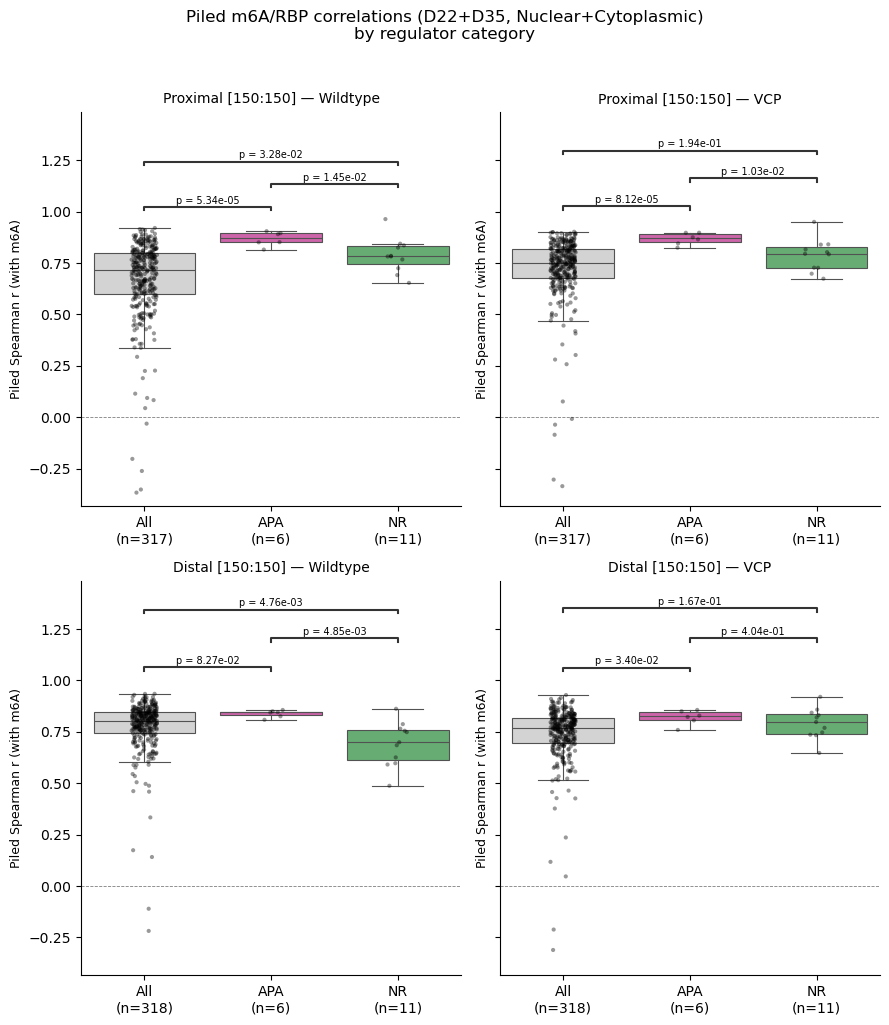

In [34]:
iso_labels = {'proximal': 'Proximal', 'distal': 'Distal'}
iso_windows = {'proximal': f'[{dist_min}:{dist_max_prox}]', 'distal': f'[{dist_min}:{dist_max_prox}]'}
genotypes_plot = ['Wildtype', 'VCP']

fig, axes = plt.subplots(2, 2, figsize=(9, 10), sharey=True)
for row, iso in enumerate(['proximal', 'distal']):
    for col, geno in enumerate(genotypes_plot):
        group = f"D22D35_allCompartments_{geno}"
        sub_df = correlations_piled_D22D35_df[
            (correlations_piled_D22D35_df['group'] == group) &
            (correlations_piled_D22D35_df['Isoform'] == iso)
        ]
        plot_category_box(axes[row, col], sub_df, f"{iso_labels[iso]} {iso_windows[iso]} — {geno}")

        # axes[row, col].set_ylim()
plt.suptitle("Piled m6A/RBP correlations (D22+D35, Nuclear+Cytoplasmic)\nby regulator category",
             fontsize=12, y=1.02)
plt.tight_layout()
save_figure(f"{figures_subfolder}/boxplot_piled_m6A_RBP_correlation_D22_D35_APA_NR_vs_all_proximal_{iso_windows['proximal']}_distal_{iso_windows['distal']}.pdf",
            legend="Piled correlation: for each CLIP dataset and genotype, the Welch profiles of several conditions are concatenated (aligned on the bin) and correlated (Pearson) with the m6A profiles concatenated the same way (bins from -150 to +150 nt around the pPAS for the proximal isoform, -150 to 0 nt around the dPAS for the distal isoform; > 10 bins). Here: D22 and D35, nuclear and cytoplasmic fractions piled. Boxplots per category, R2 regulators of lengthening (Figure_regulators_lengthening.ipynb) classified APA (pink) or nuclear retention (NR, green) vs all other CLIP datasets (All/Other, grey), "
                   "for the proximal (top) and distal (bottom) isoform, CTRL (left) and VCP (right); one dot per CLIP "
                   "dataset. Two-sided Mann-Whitney U for each pair of categories (uncorrected). The y-axis label says Spearman, but r is a Pearson correlation.")
plt.show()


### All-days-piled correlations — Nuclear/Cytoplasmic x WT/VCP, Proximal vs Distal


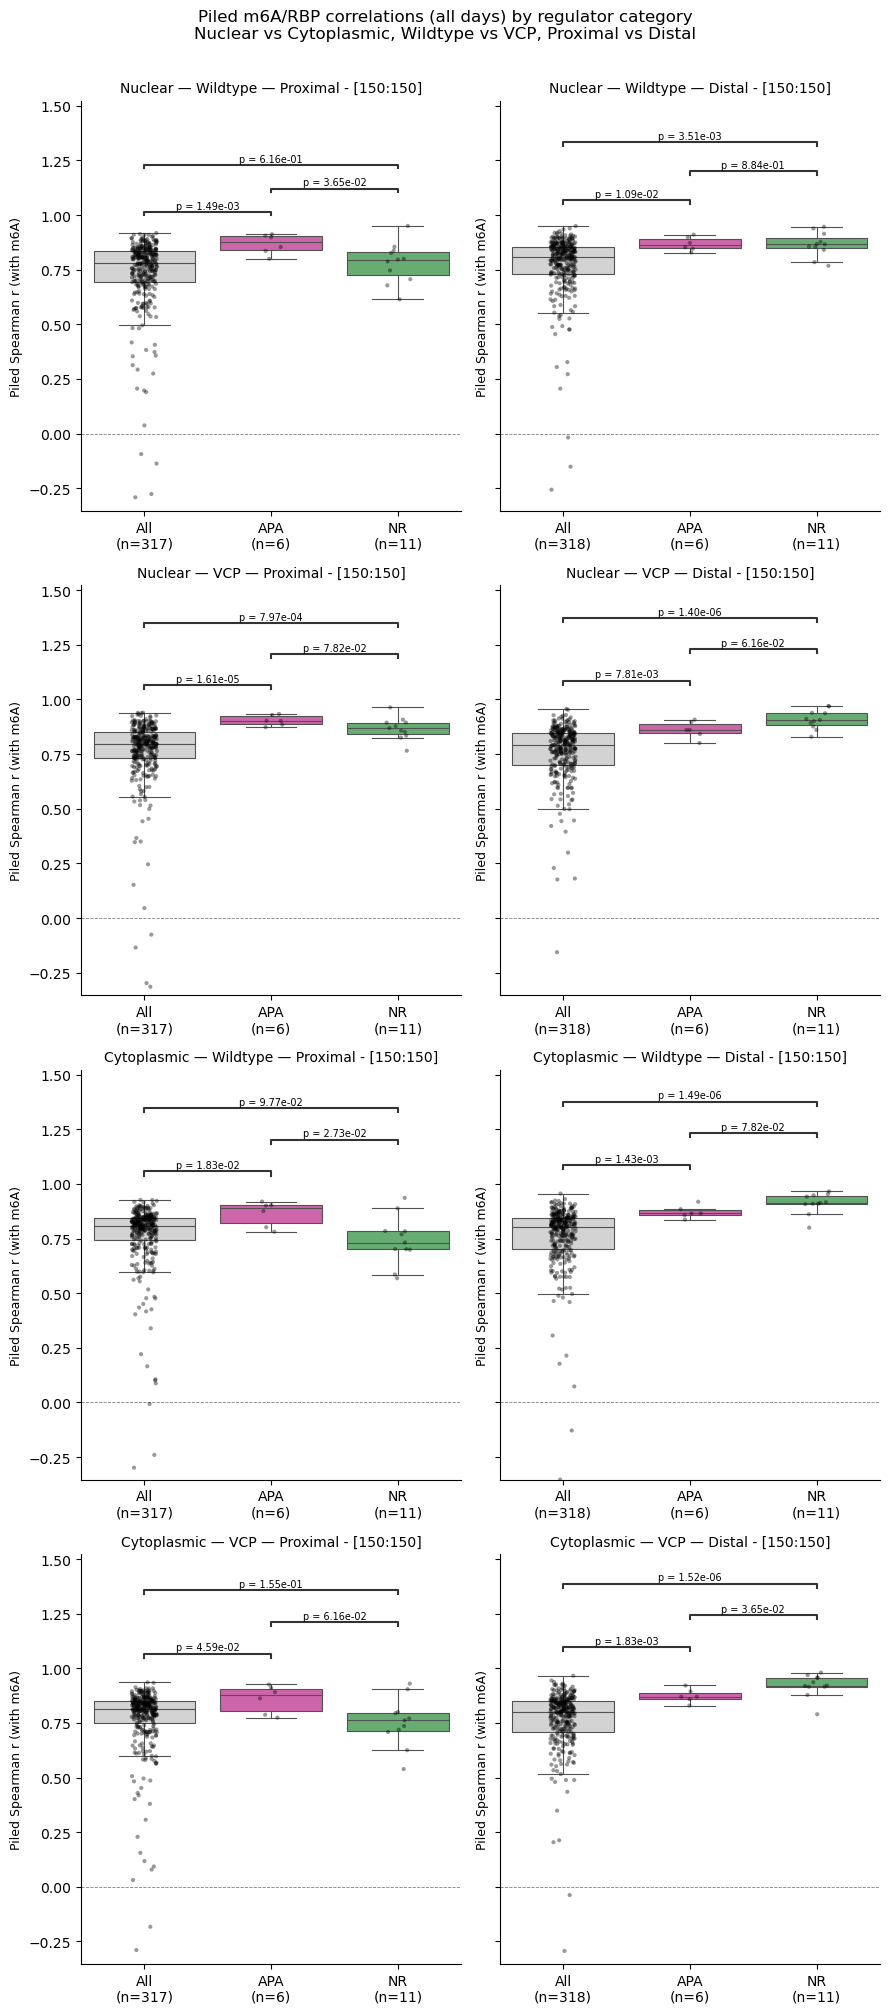

In [35]:
alldays_groups = [
    ('Nuclear', 'Wildtype'), ('Nuclear', 'VCP'),
    ('Cytoplasmic', 'Wildtype'), ('Cytoplasmic', 'VCP'),
]

fig, axes = plt.subplots(4, 2, figsize=(9, 20), sharey=True)
for row, (comp, geno) in enumerate(alldays_groups):
    group = f"allDays_{comp}_{geno}"
    for col, iso in enumerate(['proximal', 'distal']):
        sub_df = correlations_piled_alldays_df[
            (correlations_piled_alldays_df['group'] == group) &
            (correlations_piled_alldays_df['Isoform'] == iso)
        ]
        plot_category_box(axes[row, col], sub_df, f"{comp} — {geno} — {iso_labels[iso]} - {iso_windows[iso]}")

plt.suptitle("Piled m6A/RBP correlations (all days) by regulator category\n"
             "Nuclear vs Cytoplasmic, Wildtype vs VCP, Proximal vs Distal",
             fontsize=12, y=1.005)
plt.tight_layout()
save_figure(f"{figures_subfolder}/boxplot_piled_m6A_RBP_correlation_all_days_APA_NR_vs_all_proximal_{iso_windows['proximal']}_distal_{iso_windows['distal']}.pdf",
            legend="Piled correlation: for each CLIP dataset and genotype, the Welch profiles of several conditions are concatenated (aligned on the bin) and correlated (Pearson) with the m6A profiles concatenated the same way (bins from -150 to +150 nt around the pPAS for the proximal isoform, -150 to 0 nt around the dPAS for the distal isoform; > 10 bins). Here: the 6 days (D0-D35) of one fraction piled. Boxplots per category, R2 regulators of lengthening (Figure_regulators_lengthening.ipynb) classified APA (pink) or nuclear retention (NR, green) vs all other CLIP datasets (All/Other, grey); rows = "
                   "nuclear CTRL, nuclear VCP, cytoplasmic CTRL, cytoplasmic VCP; columns = proximal / distal isoform; "
                   "one dot per CLIP dataset. Two-sided Mann-Whitney U for each pair of categories (uncorrected). The y-axis label says Spearman, but r is a Pearson correlation.")
plt.show()


In [36]:
# # Heatmap: one row per RBP CLIP dataset, one column per (Compartment, Genotype, Isoform) piled r
# heatmap_cols = [
#     (comp, geno, iso)
#     for iso in ['proximal', 'distal']
#     for (comp, geno) in alldays_groups
# ]
# heatmap_df = (
#     correlations_piled_alldays_df
#     .assign(column=lambda d: d['group'].str.replace('allDays_', '', regex=False) + '_' + d['Isoform'])
#     .pivot_table(index='RBP', columns='column', values='r')
# )
# heatmap_df = heatmap_df[[f"{comp}_{geno}_{iso}" for comp, geno, iso in heatmap_cols]]
# heatmap_df.columns = [f"{comp} — {geno} — {iso_labels[iso]}" for comp, geno, iso in heatmap_cols]

# rbp_category = correlations_piled_alldays_df.drop_duplicates('RBP').set_index('RBP')['category']
# row_colors = rbp_category.reindex(heatmap_df.index).map(cat_palette).rename('Category')

# g = sns.clustermap(
#     heatmap_df.fillna(0), mask=heatmap_df.isna(),
#     row_cluster=True, col_cluster=False, row_colors=row_colors,
#     cmap='RdBu_r', center=0, vmin=-1, vmax=1,
#     yticklabels=True, xticklabels=True,
#     figsize=(7, 0.13 * len(heatmap_df) + 2),
#     dendrogram_ratio=(0.1, 0.01), cbar_pos=(1.02, 0.9, 0.03, 0.08),
#     cbar_kws={'label': 'Piled r (with m6A)'},
# )
# g.ax_heatmap.tick_params(axis='y', labelsize=5)
# g.ax_heatmap.tick_params(axis='x', labelsize=8)
# plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right')
# g.ax_heatmap.axvline(len(alldays_groups), color='black', lw=1)  # proximal | distal
# g.ax_heatmap.set_xlabel('')
# g.ax_heatmap.set_ylabel('')
# for c in cat_order:
#     g.ax_row_colors.bar(0, 0, color=cat_palette[c], label=c)
# g.ax_row_colors.legend(title='Category', loc='lower left', bbox_to_anchor=(0, 1.0), frameon=False, fontsize=7, title_fontsize=8)
# g.figure.suptitle("Piled m6A/RBP correlations (all days) per RBP", y=1.01, fontsize=12)
# save_figure(f"{figures_subfolder}/heatmap_piled_m6A_RBP_correlation_all_days_per_CLIP.pdf",
#             legend="Piled correlation: for each CLIP dataset and genotype, the Welch profiles of several conditions are concatenated (aligned on the bin) and correlated (Pearson) with the m6A profiles concatenated the same way (bins from -150 to +150 nt around the pPAS for the proximal isoform, -150 to 0 nt around the dPAS for the distal isoform; > 10 bins). Here: the 6 days (D0-D35) of one fraction piled. One row per CLIP dataset (clustered; side "
#                    "colour = category: All grey, APA pink, NR green), columns = fraction x genotype for the proximal "
#                    "(left 4) and distal (right 4) isoform. Colour = Pearson r (-1 to 1); blank = not computed.")
# plt.show()

## Welch profiles by regulator category vs m6A — Nuclear Wildtype, Proximal isoform

For the Nuclear/Wildtype condition and the proximal isoform, the median `mean_score_lg10` Welch profile (across `dist`) is plotted per regulator category (`All`, `NR`, `APA`, using the same `classify_regulator` split as above), together with the m6A profile, for D22 and D35 side by side.


In [37]:
profile_cat_palette = dict(cat_palette)
profile_cat_palette['All'] = '#8c8c8c'
profile_cat_palette['m6A'] = '#e7872b'
profile_cat_order = ['All', 'NR', 'APA', 'm6A']

def get_median_welch_profile(rbp_df, day, compartment, genotype, isoform_label,
                              dist_min=-1000, dist_max=150):
    """Median mean_score_lg10 at each dist, split by regulator category."""
    sub = rbp_df[
        (rbp_df['Day'] == day) & (rbp_df['Compartment'] == compartment) &
        (rbp_df['VCP'] == genotype) & (rbp_df['Isoform'] == isoform_label) &
        (rbp_df['dist'] >= dist_min) & (rbp_df['dist'] <= dist_max)
    ].copy()
    sub['category'] = sub['CLIP'].apply(classify_regulator)
    return sub.groupby(['category', 'dist'])['mean_score_lg10'].median().reset_index()

def get_m6a_profile(m6a_df, day, compartment, genotype, isoform_label,
                     dist_min=-1000, dist_max=150):
    sub = m6a_df[
        (m6a_df['Day'] == day) & (m6a_df['Compartment'] == compartment) &
        (m6a_df['VCP'] == genotype) & (m6a_df['Isoform'] == isoform_label) &
        (m6a_df['dist'] >= dist_min) & (m6a_df['dist'] <= dist_max)
    ]
    return sub.groupby('dist')['mean_score_lg10'].median().reset_index()

def plot_welch_profiles(ax, rbp_df, m6a_df, day, compartment, genotype, isoform_label):
    cat_profiles = get_median_welch_profile(rbp_df, day, compartment, genotype, isoform_label)
    m6a_profile = get_m6a_profile(m6a_df, day, compartment, genotype, isoform_label)

    for cat in ['All', 'NR', 'APA']:
        cat_data = cat_profiles[cat_profiles['category'] == cat].sort_values('dist')
        ax.plot(cat_data['dist'], cat_data['mean_score_lg10'],
                color=profile_cat_palette[cat], label=cat, linewidth=2)

    m6a_profile = m6a_profile.sort_values('dist')
    ax.plot(m6a_profile['dist'], m6a_profile['mean_score_lg10'],
            color=profile_cat_palette['m6A'], label='m6A', linewidth=2, linestyle='--')

    ax.set_title(f"{day} — {compartment} — {genotype}", fontsize=11)
    ax.set_xlabel('Distance from PAS (nt)', fontsize=9)
    sns.despine(ax=ax)


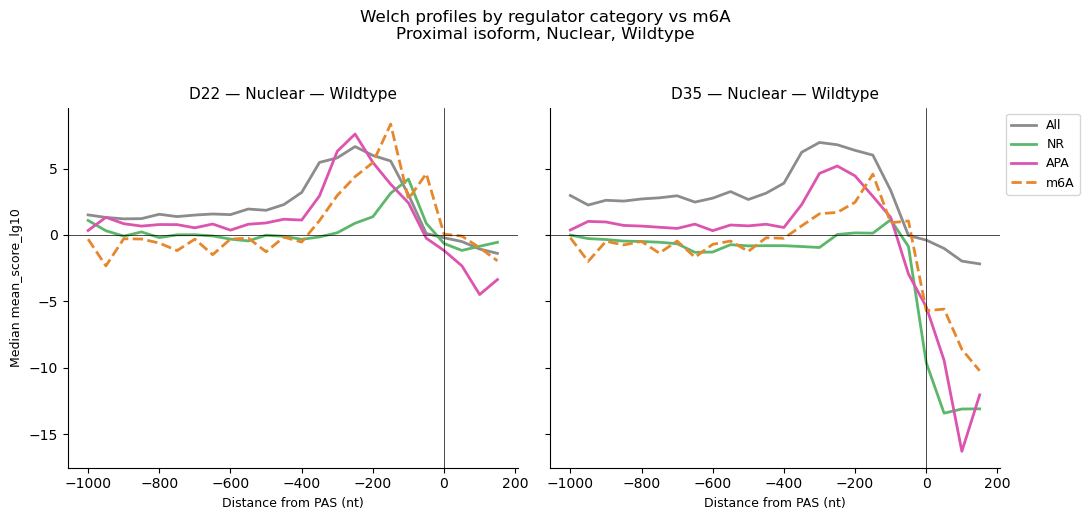

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

for ax, day in zip(axes, ['D22', 'D35']):
    plot_welch_profiles(ax, proximal, proximal_m6A, day, 'Nuclear', 'Wildtype',
                         "Proximal 3'UTR Isoform")
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.axvline(x=0, color='black', linewidth=0.5)


axes[0].set_ylabel('Median mean_score_lg10', fontsize=9)
axes[1].legend(title='', bbox_to_anchor=(1, 1), loc='upper left', fontsize=9)

plt.suptitle("Welch profiles by regulator category vs m6A\nProximal isoform, Nuclear, Wildtype",
             fontsize=12, y=1.03)
plt.tight_layout()
save_figure(f"{figures_subfolder}/lineplot_median_welch_profile_APA_NR_all_vs_m6A_proximal_Nuclear_Wildtype_D22_D35.pdf",
            legend="Median Welch score per 50-nt bin (-1000 to +150 nt around the pPAS, proximal isoform) of all other "
                   "CLIP datasets (grey), the R2 nuclear-retention (green) and APA (pink) regulators of lengthening, and "
                   "the m6A Welch profile (orange, dashed), nuclear fraction of CTRL motor neurons at D22 (left) "
                   "and D35 (right).")
plt.show()


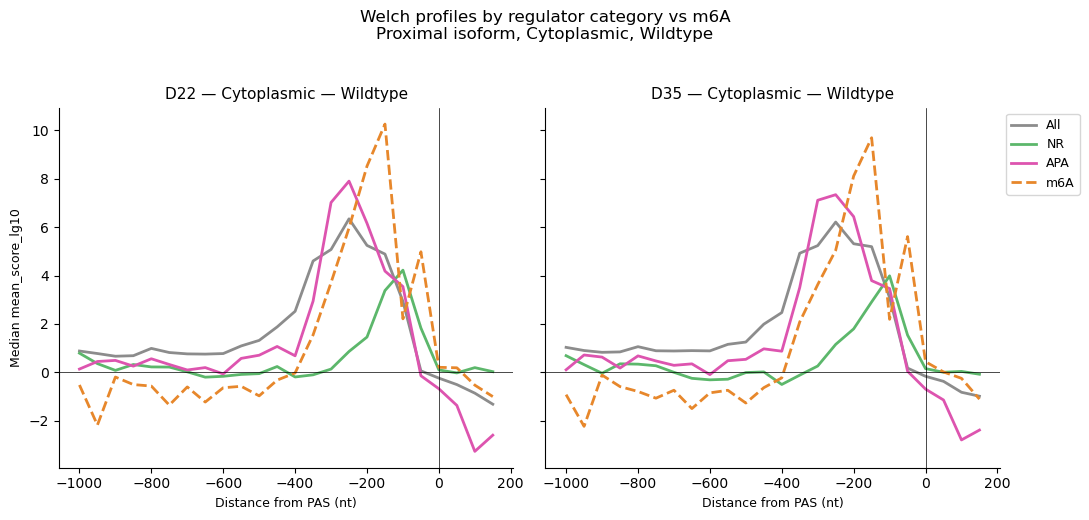

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

for ax, day in zip(axes, ['D22', 'D35']):
    plot_welch_profiles(ax, proximal, proximal_m6A, day, 'Cytoplasmic', 'Wildtype',
                         "Proximal 3'UTR Isoform")
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.axvline(x=0, color='black', linewidth=0.5)

axes[0].set_ylabel('Median mean_score_lg10', fontsize=9)
axes[1].legend(title='', bbox_to_anchor=(1, 1), loc='upper left', fontsize=9)

plt.suptitle("Welch profiles by regulator category vs m6A\nProximal isoform, Cytoplasmic, Wildtype",
             fontsize=12, y=1.03)
plt.tight_layout()
save_figure(f"{figures_subfolder}/lineplot_median_welch_profile_APA_NR_all_vs_m6A_proximal_Cytoplasmic_Wildtype_D22_D35.pdf",
            legend="Median Welch score per 50-nt bin (-1000 to +150 nt around the pPAS, proximal isoform) of all other "
                   "CLIP datasets (grey), the R2 nuclear-retention (green) and APA (pink) regulators of lengthening, and "
                   "the m6A Welch profile (orange, dashed), cytoplasmic fraction of CTRL motor neurons at D22 (left) "
                   "and D35 (right).")
plt.show()


### D35 Nuclear Wildtype — proximal vs distal isoform

Same median Welch profiles per regulator category, D35 Nuclear Wildtype, proximal (around the pPAS) next to distal (around the dPAS) isoform (distal: sign reversed, independent y scale); below, the Pearson correlation (shape), the RMSE (absolute distance) and Lin's concordance correlation coefficient (CCC: 1 = identical profiles, penalises shape, scale and offset differences) between the NR / APA (and All, as reference) median profiles and the m6A profile, one score per isoform, summarised as a barplot.

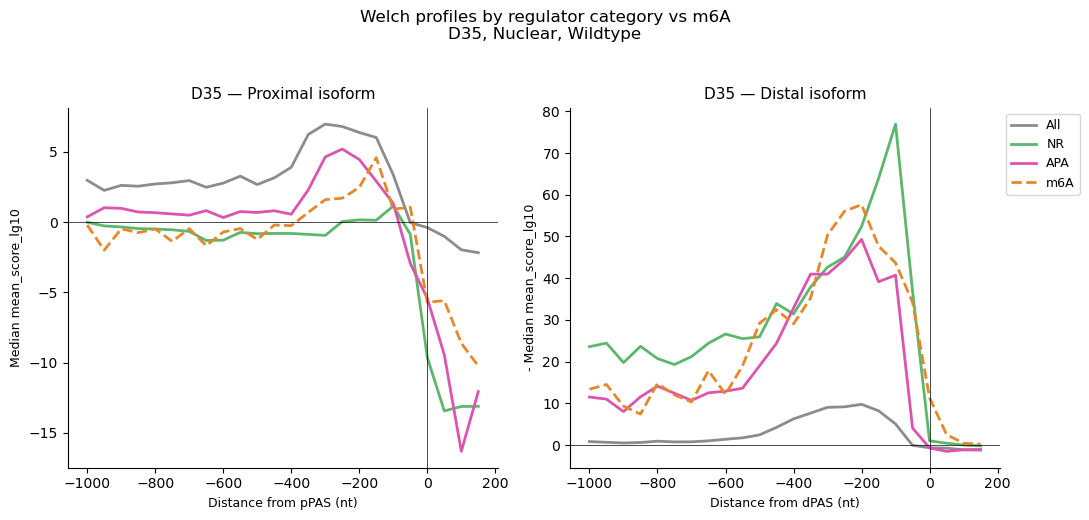

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Distal: sign of the Welch scores reversed (RBPs and m6A alike)
flip = lambda df: df.assign(mean_score_lg10=-df['mean_score_lg10'])
for ax, (rbp_df, m6a_df, iso_label) in zip(axes, [(proximal, proximal_m6A, "Proximal 3'UTR Isoform"),
                                                   (flip(distal), flip(distal_m6A), "Distal 3'UTR Isoform")]):
    plot_welch_profiles(ax, rbp_df, m6a_df, 'D35', 'Nuclear', 'Wildtype', iso_label)
    ax.set_title(f"D35 — {iso_label.split(' ')[0]} isoform", fontsize=11)
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.axvline(x=0, color='black', linewidth=0.5)

axes[0].set_xlabel('Distance from pPAS (nt)', fontsize=9)
axes[1].set_xlabel('Distance from dPAS (nt)', fontsize=9)
axes[0].set_ylabel('Median mean_score_lg10', fontsize=9)
axes[1].set_ylabel('- Median mean_score_lg10', fontsize=9)
axes[1].legend(title='', bbox_to_anchor=(1, 1), loc='upper left', fontsize=9)

plt.suptitle("Welch profiles by regulator category vs m6A\nD35, Nuclear, Wildtype",
             fontsize=12, y=1.03)
plt.tight_layout()
save_figure(f"{figures_subfolder}/lineplot_median_welch_profile_APA_NR_all_vs_m6A_proximal_distal_Nuclear_Wildtype_D35.pdf",
            legend="Median Welch score per 50-nt bin (-1000 to +150 nt around the PAS) of all other CLIP datasets "
                   "(grey), the R2 nuclear-retention (green) and APA (pink) regulators of lengthening, and the m6A "
                   "Welch profile (orange, dashed), nuclear fraction of CTRL motor neurons at D35, proximal isoform "
                   "(left, around the pPAS) and distal isoform (right, around the dPAS; sign reversed, so that "
                   "positive values mean enrichment on the distal isoform). Independent y scales.")
plt.show()

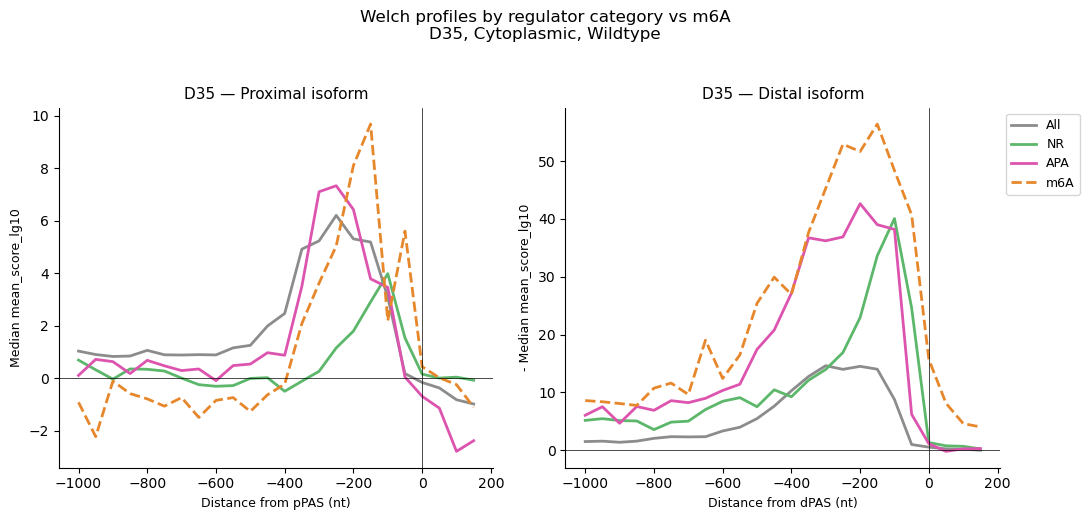

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Distal: sign of the Welch scores reversed (RBPs and m6A alike)
flip = lambda df: df.assign(mean_score_lg10=-df['mean_score_lg10'])
for ax, (rbp_df, m6a_df, iso_label) in zip(axes, [(proximal, proximal_m6A, "Proximal 3'UTR Isoform"),
                                                   (flip(distal), flip(distal_m6A), "Distal 3'UTR Isoform")]):
    plot_welch_profiles(ax, rbp_df, m6a_df, 'D35', 'Cytoplasmic', 'Wildtype', iso_label)
    ax.set_title(f"D35 — {iso_label.split(' ')[0]} isoform", fontsize=11)
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.axvline(x=0, color='black', linewidth=0.5)

axes[0].set_xlabel('Distance from pPAS (nt)', fontsize=9)
axes[1].set_xlabel('Distance from dPAS (nt)', fontsize=9)
axes[0].set_ylabel('Median mean_score_lg10', fontsize=9)
axes[1].set_ylabel('- Median mean_score_lg10', fontsize=9)
axes[1].legend(title='', bbox_to_anchor=(1, 1), loc='upper left', fontsize=9)

plt.suptitle("Welch profiles by regulator category vs m6A\nD35, Cytoplasmic, Wildtype",
             fontsize=12, y=1.03)
plt.tight_layout()
save_figure(f"{figures_subfolder}/lineplot_median_welch_profile_APA_NR_all_vs_m6A_proximal_distal_Cytoplasmic_Wildtype_D35.pdf",
            legend="Median Welch score per 50-nt bin (-1000 to +150 nt around the PAS) of all other CLIP datasets "
                   "(grey), the R2 nuclear-retention (green) and APA (pink) regulators of lengthening, and the m6A "
                   "Welch profile (orange, dashed), cytoplasmic fraction of CTRL motor neurons at D35, proximal isoform "
                   "(left, around the pPAS) and distal isoform (right, around the dPAS; sign reversed, so that "
                   "positive values mean enrichment on the distal isoform). Independent y scales.")
plt.show()

In [42]:
# Pearson correlation (shape only: invariant to scale/offset), RMSE (absolute distance, in
# mean_score_lg10 units) and Lin's concordance correlation coefficient
# (CCC = 1 - MSE / (var_x + var_y + (mean_x - mean_y)^2); 1 = identical profiles) between each category's median Welch profile and the m6A profile
# (bins aligned on dist, same -1000 to +150 nt window as the plot above), D35 Nuclear Wildtype.
profile_corr_records = []
for iso_label, rbp_df, m6a_df in [("Proximal 3'UTR Isoform", proximal, proximal_m6A),
                                  ("Distal 3'UTR Isoform", distal, distal_m6A)]:
    cat_profiles = get_median_welch_profile(rbp_df, 'D35', 'Nuclear', 'Wildtype', iso_label)
    m6a_profile = get_m6a_profile(m6a_df, 'D35', 'Nuclear', 'Wildtype', iso_label).set_index('dist')['mean_score_lg10']
    for cat in ['NR', 'APA', 'All']:
        cat_series = cat_profiles[cat_profiles['category'] == cat].set_index('dist')['mean_score_lg10']
        aligned = cat_series.to_frame('rbp').join(m6a_profile.rename('m6A'), how='inner').dropna()
        n, r, p = safe_pearsonr(aligned['m6A'].to_numpy(), aligned['rbp'].to_numpy())
        mse = np.mean((aligned['rbp'] - aligned['m6A']) ** 2)
        rmse = np.sqrt(mse)
        ccc = 1 - mse / (aligned['rbp'].var(ddof=0) + aligned['m6A'].var(ddof=0)
                         + (aligned['rbp'].mean() - aligned['m6A'].mean()) ** 2)
        profile_corr_records.append({'Isoform': iso_label, 'category': cat, 'n_bins': n, 'r': r, 'p_value': p,
                                     'RMSE': rmse, 'CCC': ccc})

median_profile_m6A_corr = pd.DataFrame(profile_corr_records)
median_profile_m6A_corr.pivot(index='category', columns='Isoform', values=['r', 'RMSE', 'CCC']).loc[['NR', 'APA', 'All']]

r                                        RMSE  \
Isoform  Distal 3'UTR Isoform Proximal 3'UTR Isoform Distal 3'UTR Isoform   
category                                                                    
NR                   0.859507               0.894109            10.794550   
APA                  0.909500               0.904164             8.553331   
All                  0.916864               0.859802            24.960191   

                                                 CCC                         
Isoform  Proximal 3'UTR Isoform Distal 3'UTR Isoform Proximal 3'UTR Isoform  
category                                                                     
NR                     2.509452             0.826929               0.807023  
APA                    2.567917             0.872069               0.820388  
All                    4.299257             0.152962               0.433925

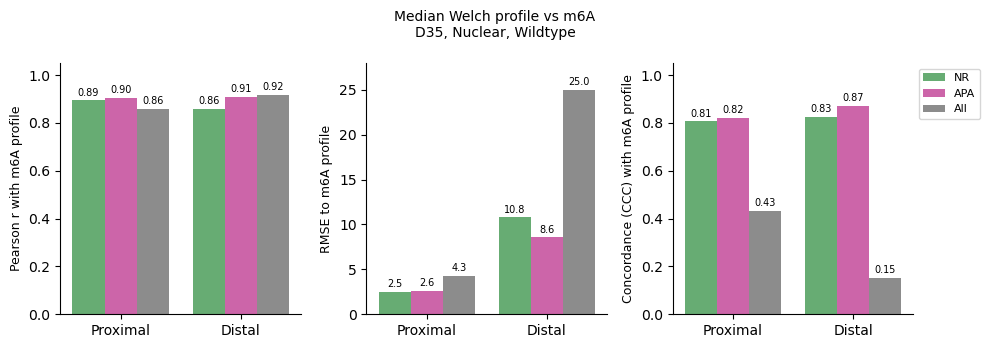

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
bar_df = median_profile_m6A_corr.assign(Isoform=median_profile_m6A_corr['Isoform'].str.split(' ').str[0])
for ax, metric, ylabel, fmt in [(axes[0], 'r', 'Pearson r with m6A profile', '%.2f'),
                                (axes[1], 'RMSE', 'RMSE to m6A profile', '%.1f'),
                                (axes[2], 'CCC', 'Concordance (CCC) with m6A profile', '%.2f')]:
    sns.barplot(data=bar_df, x='Isoform', y=metric, hue='category', hue_order=['NR', 'APA', 'All'],
                palette=profile_cat_palette, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, fontsize=7, padding=2)
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel, fontsize=9)
    sns.despine(ax=ax)
axes[0].set_ylim(min(0, bar_df['r'].min() - 0.1), 1.05)
axes[1].set_ylim(0, bar_df['RMSE'].max() * 1.12)
axes[2].set_ylim(min(0, bar_df['CCC'].min() - 0.1), 1.05)
for ax in axes[:2]:
    ax.get_legend().remove()
axes[2].legend(title='', bbox_to_anchor=(1, 1), loc='upper left', fontsize=8)
plt.suptitle("Median Welch profile vs m6A\nD35, Nuclear, Wildtype", fontsize=10)
plt.tight_layout()
save_figure(f"{figures_subfolder}/barplot_median_welch_profile_APA_NR_all_vs_m6A_correlation_proximal_distal_Nuclear_Wildtype_D35.pdf",
            legend="Similarity between the median Welch profile (50-nt bins, -1000 to +150 nt around the PAS; 24 bins) "
                   "of the R2 nuclear-retention (green) and APA (pink) regulators of lengthening, or of all other CLIP "
                   "datasets (grey), and the m6A Welch profile, nuclear fraction of CTRL motor neurons at D35, proximal "
                   "(around the pPAS) and distal (around the dPAS) isoform. Left: Pearson r (profile shape, insensitive "
                   "to scale and offset). Middle: root-mean-square error between the two profiles (mean_score_lg10 units; "
                   "lower = closer in absolute values). Right: Lin's concordance correlation coefficient "
                   "(1 - MSE / (var + var + squared mean difference); 1 = identical profiles, lower when shape, "
                   "amplitude or offset differ).")
plt.show()

In [44]:
# Pearson correlation (shape only: invariant to scale/offset), RMSE (absolute distance, in
# mean_score_lg10 units) and Lin's concordance correlation coefficient
# (CCC = 1 - MSE / (var_x + var_y + (mean_x - mean_y)^2); 1 = identical profiles) between each category's median Welch profile and the m6A profile
# (bins aligned on dist, same -1000 to +150 nt window as the plot above), D35 Cytoplasmic Wildtype.
profile_corr_records = []
for iso_label, rbp_df, m6a_df in [("Proximal 3'UTR Isoform", proximal, proximal_m6A),
                                  ("Distal 3'UTR Isoform", distal, distal_m6A)]:
    cat_profiles = get_median_welch_profile(rbp_df, 'D35', 'Cytoplasmic', 'Wildtype', iso_label)
    m6a_profile = get_m6a_profile(m6a_df, 'D35', 'Cytoplasmic', 'Wildtype', iso_label).set_index('dist')['mean_score_lg10']
    for cat in ['NR', 'APA', 'All']:
        cat_series = cat_profiles[cat_profiles['category'] == cat].set_index('dist')['mean_score_lg10']
        aligned = cat_series.to_frame('rbp').join(m6a_profile.rename('m6A'), how='inner').dropna()
        n, r, p = safe_pearsonr(aligned['m6A'].to_numpy(), aligned['rbp'].to_numpy())
        mse = np.mean((aligned['rbp'] - aligned['m6A']) ** 2)
        rmse = np.sqrt(mse)
        ccc = 1 - mse / (aligned['rbp'].var(ddof=0) + aligned['m6A'].var(ddof=0)
                         + (aligned['rbp'].mean() - aligned['m6A'].mean()) ** 2)
        profile_corr_records.append({'Isoform': iso_label, 'category': cat, 'n_bins': n, 'r': r, 'p_value': p,
                                     'RMSE': rmse, 'CCC': ccc})

median_profile_m6A_corr_cyto = pd.DataFrame(profile_corr_records)
median_profile_m6A_corr_cyto.pivot(index='category', columns='Isoform', values=['r', 'RMSE', 'CCC']).loc[['NR', 'APA', 'All']]

r                                        RMSE  \
Isoform  Distal 3'UTR Isoform Proximal 3'UTR Isoform Distal 3'UTR Isoform   
category                                                                    
NR                   0.860732               0.683732            16.182432   
APA                  0.902212               0.687597            10.529037   
All                  0.876253               0.708921            22.202739   

                                                 CCC                         
Isoform  Proximal 3'UTR Isoform Distal 3'UTR Isoform Proximal 3'UTR Isoform  
category                                                                     
NR                     2.546914             0.532659               0.406938  
APA                    2.319989             0.799669               0.674141  
All                    2.330691             0.239905               0.623400

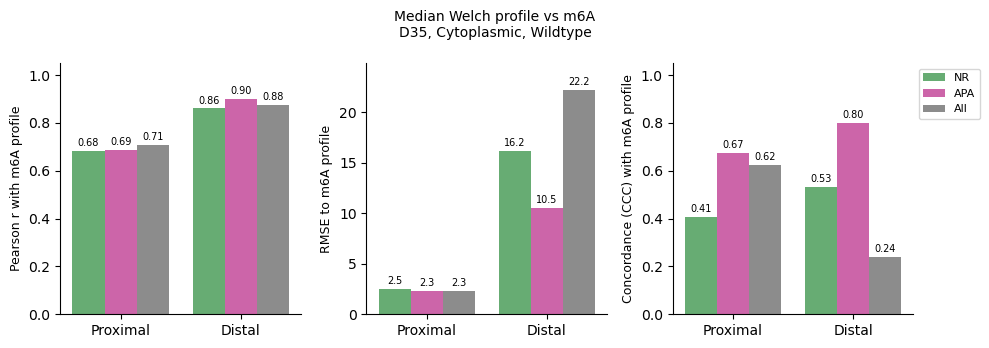

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
bar_df = median_profile_m6A_corr_cyto.assign(Isoform=median_profile_m6A_corr_cyto['Isoform'].str.split(' ').str[0])
for ax, metric, ylabel, fmt in [(axes[0], 'r', 'Pearson r with m6A profile', '%.2f'),
                                (axes[1], 'RMSE', 'RMSE to m6A profile', '%.1f'),
                                (axes[2], 'CCC', 'Concordance (CCC) with m6A profile', '%.2f')]:
    sns.barplot(data=bar_df, x='Isoform', y=metric, hue='category', hue_order=['NR', 'APA', 'All'],
                palette=profile_cat_palette, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, fontsize=7, padding=2)
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel, fontsize=9)
    sns.despine(ax=ax)
axes[0].set_ylim(min(0, bar_df['r'].min() - 0.1), 1.05)
axes[1].set_ylim(0, bar_df['RMSE'].max() * 1.12)
axes[2].set_ylim(min(0, bar_df['CCC'].min() - 0.1), 1.05)
for ax in axes[:2]:
    ax.get_legend().remove()
axes[2].legend(title='', bbox_to_anchor=(1, 1), loc='upper left', fontsize=8)
plt.suptitle("Median Welch profile vs m6A\nD35, Cytoplasmic, Wildtype", fontsize=10)
plt.tight_layout()
save_figure(f"{figures_subfolder}/barplot_median_welch_profile_APA_NR_all_vs_m6A_correlation_proximal_distal_Cytoplasmic_Wildtype_D35.pdf",
            legend="Similarity between the median Welch profile (50-nt bins, -1000 to +150 nt around the PAS; 24 bins) "
                   "of the R2 nuclear-retention (green) and APA (pink) regulators of lengthening, or of all other CLIP "
                   "datasets (grey), and the m6A Welch profile, cytoplasmic fraction of CTRL motor neurons at D35, proximal "
                   "(around the pPAS) and distal (around the dPAS) isoform. Left: Pearson r (profile shape, insensitive "
                   "to scale and offset). Middle: root-mean-square error between the two profiles (mean_score_lg10 units; "
                   "lower = closer in absolute values). Right: Lin's concordance correlation coefficient "
                   "(1 - MSE / (var + var + squared mean difference); 1 = identical profiles, lower when shape, "
                   "amplitude or offset differ).")
plt.show()